# Replicating Bottomly et al. (2022), *Cancer Cell*
### "Integrative analysis of drug response and clinical outcome in acute myeloid leukemia"

This notebook re-runs the main analyses of the paper on the public Beat AML 2.0 data, one figure at a time.
It is written to explain **what the authors did, why, and how to read each result**, as well as to reproduce the numbers.

**How each section is laid out**

1. **The question**: what the paper is trying to find out in that figure.
2. **Inputs**: which data go in, and how many patients.
3. **Method**: the statistics, explained in plain language the first time each one appears.
4. **Code + output**
5. **Interpretation**: what the output means, and whether it matches the paper.

**Where the method details came from.** The paper's STAR Methods are brief. Wherever they leave a choice open
(which samples, which test, which threshold), this notebook follows the authors' own R code
([biodev/beataml2_manuscript](https://github.com/biodev/beataml2_manuscript), cloned locally by
`scripts/get_manuscript_code.sh`). Places where Python cannot do exactly what R did are flagged with **⚠ Deviation**.

**Environment.** Run with the `bioinfo` conda env from the repo root's `notebooks/` folder. Needs: numpy, pandas, scipy,
statsmodels, lifelines, scikit-survival, scikit-learn, matplotlib, seaborn.

## The paper in one paragraph

Beat AML collected leukemia cells from ~800 AML patients and measured, for each one, (i) **DNA mutations**,
(ii) **RNA-seq gene expression**, (iii) **ex vivo drug sensitivity**: the patient's cells are put in wells with
~120 drugs at 7 doses, and the area under the dose–response curve (**AUC**) is recorded (low AUC = cells died easily = *sensitive*),
and (iv) **clinical outcome** (survival). The first paper (Tyner 2018, "Waves 1+2") was extended with new patients ("Waves 3+4").
This paper:

| Part | Question | Figures | Answer in the paper |
|---|---|---|---|
| 1 | Do the new patients look like the old ones? | Fig 1 | Yes: same mutations, survival, drug responses; 89% of old mutation–drug findings replicate |
| 2 | How "mature" is each tumor? | Fig 2, S2 | Score each tumor against 6 single-cell AML cell-type signatures (van Galen 2019) using **PC1** |
| 3 | Does tumor maturation state affect drug response? | Fig 3, S3 | Yes: 73 drugs correlate with at least one cell-type score; some mutation effects depend on cell type |
| 4 | Do drug *families* behave similarly? | Fig 4, 5 | Families (grouped by target) show mutation and cell-type associations |
| 5 | What predicts survival? | Fig 6, 7 | Age, TP53, and WGCNA **Module 3**, whose hub gene is **PEAR1**; PEAR1 alone does about as well as the 17-gene LSC17 score |

Part 2 is the one this project builds on: the **six PC1 cell-type scores** are the baseline that the β-VAE/NMF features
will be compared against.

## A short statistics glossary

Each of these is explained again where it is first used. This is the cheat sheet.

| Term | One-line meaning |
|---|---|
| **z-score / "center and scale"** | Subtract the mean and divide by the SD, so every gene is on the same unitless scale (mean 0, SD 1). |
| **PCA / PC1** | Finds the single direction through a set of correlated genes that captures the most variation. A sample's **PC1 score** is its position along that direction: one number that summarizes many genes. |
| **Pearson r** | Linear correlation, −1 to +1. |
| **Welch's t-test** | Tests whether two groups (e.g. mutated vs wild-type) have different means, without assuming equal variances. |
| **Glass's Δ** | Effect size: (mean of mutated − mean of wild-type) / SD of wild-type. "How many wild-type SDs apart." |
| **p-value** | Probability of a result at least this extreme if there were truly no effect. |
| **Multiple testing** | Running 1,000 tests at p<0.05 gives ~50 false positives by chance. Corrections fix this. |
| **FDR / q-value** | False discovery rate: among results called significant, the expected *fraction* that are false. q<0.05 means "≤5% of my hits are expected to be false". Two flavors are used here: **Storey q-value** and **Benjamini–Yekutieli (BY)**, a more conservative one. |
| **Interaction term** | In a regression `y ~ a + b + a×b`, the `a×b` coefficient asks: *does the effect of b depend on a?* |
| **Censoring** | A patient who is alive at last follow-up: we know they survived *at least* that long, not their true survival time. |
| **Kaplan–Meier (KM) curve** | Estimated fraction still alive over time, correctly handling censoring. |
| **Log-rank test** | Tests whether two KM curves differ. |
| **Cox model / hazard ratio (HR)** | Regression for survival. HR = 2 means the high group dies at twice the rate at any moment; HR = 1 means no difference. |
| **Random forest / decision tree** | Tree: a flowchart of yes/no splits. Forest: average of many trees on random subsamples, more stable. |
| **ssGSEA** | Turns a ranked list (here, drugs ranked by AUC) into a score for whether a *set* (a drug family) sits near the top or bottom. |

---
## 0. Setup

In [1]:
import os, sys, warnings
from pathlib import Path

# Run from the repo root so src/ and data/ paths resolve.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
from scipy import stats
from scipy.interpolate import make_smoothing_spline
from statsmodels.stats.multitest import multipletests
import statsmodels.api as sm
from lifelines import KaplanMeierFitter, CoxPHFitter
from lifelines.statistics import logrank_test

# Project code: data loaders, and the PC1 cell-type scoring that replicates the paper.
from src.load import (load_clinical, load_expression, load_auc_long, load_pc1_baseline,
                      load_wgcna_modules, load_drug_families, FILES, CELL_TYPES)
from scripts.replication_vangalen_scores import load_signatures, paper_score

pd.set_option("display.width", 140); pd.set_option("display.max_columns", 20)
warnings.filterwarnings("ignore", category=RuntimeWarning)   # empty-slice means in paper_score, see Part 2
warnings.filterwarnings("ignore", category=FutureWarning)

# Colours: two cohorts = categorical slots 1-2; correlations = blue<->red diverging with a grey midpoint.
# Paper convention for drug response: RED = sensitive (negative correlation with AUC), BLUE = resistant.
WAVE_COL = {"Waves1+2": "#2a78d6", "Waves3+4": "#eb6834"}
DIV = LinearSegmentedColormap.from_list("div", ["#e34948", "#f0efec", "#2a78d6"])
SEQ = LinearSegmentedColormap.from_list("seq", ["#cde2fb", "#3987e5", "#0d366b"])
INK, MUTED = "#0b0b0b", "#8a8984"
mpl.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
                     "axes.edgecolor": MUTED, "font.size": 9, "axes.titlesize": 10})
print("repo root:", ROOT)

repo root: /Users/vaniahalim/Documents/CMU/F26/CM/beat-aml


---
## 1. Inputs: loading the data and defining the cohorts

### What goes in

| File (in `data/raw/`) | What it is | Unit |
|---|---|---|
| `beataml_wv1to4_clinical.xlsx` | One row per specimen: age, diagnosis, ELN risk, survival, cohort, clinical mutation calls | specimen |
| `beataml_waves1to4_norm_exp_dbgap.txt` | RNA-seq, 22,843 genes. Already normalized (CQN) and log2-scaled | gene × specimen |
| `beataml_probit_curve_fits_v4_dbgap.txt` | One row per specimen × drug: the fitted dose–response curve and its **AUC** | specimen × drug |
| `beataml_wes_wv1to4_mutations_dbgap.txt` | One row per detected mutation | variant |
| `mmc3.xlsx` | van Galen 2019 Table S3: marker genes for the 6 malignant cell types | gene list |
| `wgcna/…kme.RData` → `data/interim/wgcna_cur_map.csv` | Gene → co-expression module assignments from the 2018 paper | gene list |

### Filters (these follow `clinical.for.genomic.analysis()` in the authors' code)

* `used_manuscript_analyses == "yes"`: the authors' own selection. It keeps **one specimen per patient per data type** (the
  first timepoint) and drops remission samples. Without it, one patient could count twice.
* ELN2017 non-calls ("NonInitial", "MissingKaryo", …) → missing. Only Favorable / Intermediate / Adverse are real risk groups.
* `vitalStatus == "Unknown"` → missing. Survival ≤ 0 days → missing.
* Age groups as in the paper: **young < 45**, **middle 45–60**, **older 60–75**, **oldest > 75**.

`load_clinical()` from `src/load.py` already does the ELN / vital-status cleaning.

In [2]:
clin = load_clinical()                                       # 942 specimens, cleaned
clin = clin[clin.used_manuscript_analyses.eq("yes")].copy()  # the paper's analysis set
clin["ptid"] = "pt" + clin.dbgap_subject_id.astype(str)
clin["age_cut"] = pd.cut(clin.ageAtDiagnosis, [-1, 45, 60, 75, 100], labels=["young", "middle", "older", "oldest"])
clin["isTherapy"] = clin.specificDxAtAcquisition.eq("Therapy-related myeloid neoplasms")

# Three overlapping data types. The manuscript_* flags pick ONE specimen per patient for each.
rna_clin = clin[clin.manuscript_rnaseq.eq("yes")].set_index("ptid")
dna_clin = clin[clin.manuscript_dnaseq.eq("yes")].set_index("ptid")
inh_clin = clin[clin.manuscript_inhibitor.eq("yes")].set_index("ptid")

summary = pd.DataFrame({
    "specimens": [len(clin), len(rna_clin), len(dna_clin), len(inh_clin)],
    "Waves1+2": [clin.cohort.eq("Waves1+2").sum(), *(d.cohort.eq("Waves1+2").sum() for d in (rna_clin, dna_clin, inh_clin))],
    "Waves3+4": [clin.cohort.eq("Waves3+4").sum(), *(d.cohort.eq("Waves3+4").sum() for d in (rna_clin, dna_clin, inh_clin))],
}, index=["all used specimens", "RNA-seq (1 per patient)", "DNA-seq (1 per patient)", "drug screen (1 per patient)"])
summary

,specimens,Waves1+2,Waves3+4
all used specimens,744,510,234
RNA-seq (1 per patient),560,372,188
DNA-seq (1 per patient),713,482,231
drug screen (1 per patient),512,317,195


**Expression matrix.** We keep the 560 RNA-seq specimens and relabel rows by patient (`ptid`). Columns are gene symbols.
The values are already log-scale, so we don't transform them again.

In [3]:
expr = load_expression().droplevel(["stable_id", "description", "biotype"])   # genes x specimens, symbol index
assert not expr.index.duplicated().any()
X = expr[rna_clin.dbgap_rnaseq_sample].T          # 560 patients x 22,843 genes
X.index = rna_clin.index
is_train = rna_clin.cohort.eq("Waves1+2").to_numpy()        # Waves1+2 = the cohort parameters are fit on
is_bm = rna_clin.specimenType.eq("Bone Marrow Aspirate").to_numpy()
print("expression:", X.shape, "| Waves1+2:", is_train.sum(), "| Waves3+4:", (~is_train).sum(),
      "| bone marrow:", is_bm.sum(), "| blood/leukapheresis:", (~is_bm).sum())

expression: (560, 22843) | Waves1+2: 372 | Waves3+4: 188 | bone marrow: 308 | blood/leukapheresis: 252


**Drug screen.** `inhibitor.dataset()` in the authors' code joins drug curves to patients on `base_samp`, the specimen ID with
its D/R suffix stripped. Unlike `src.load.load_auc_long()`'s defaults, **it does not drop increasing or non-converged curves**,
so we turn those filters off here to match the paper.

The `status` column says how each drug was used: `train/test` drugs were screened in both cohorts, `combined` only in the
merged analyses, `exploratory` drugs were not analyzed.

**AUC scale.** Roughly 0–300. Higher AUC = more cells survived = **more resistant**.

In [4]:
auc_long = load_auc_long(decreasing_only=False, converged_only=False)
inh = (inh_clin.reset_index()[["dbgap_subject_id", "base_samp", "ptid", "cohort", "isDenovo"]]
       .merge(auc_long.drop(columns=["cohort"], errors="ignore"), on=["dbgap_subject_id", "base_samp"]))
assert not inh.duplicated(["ptid", "inhibitor"]).any()
print(f"{len(inh):,} patient x drug AUCs | {inh.ptid.nunique()} patients | {inh.inhibitor.nunique()} drugs")
print(inh.status.value_counts().to_string())

52,080 patient x drug AUCs | 512 patients | 166 drugs
status
train/test     41896
combined        7677
exploratory     2507


**Mutations.** Following `mutation.only.dataset()`: build a patient × gene 0/1 matrix from the exome calls. Five genes are then
overwritten with the **clinical consensus calls**: NPM1 and FLT3-ITD come from PCR assays, which sequencing misses, and RUNX1,
ASXL1 and TP53 come from manually adjudicated calls.

Waves 3+4 were sequenced with a custom capture panel, so for that cohort we keep only genes on the panel. The "combined" matrix
keeps genes present in both cohorts.

In [5]:
muts = pd.read_csv(FILES["mutations"], sep="\t", low_memory=False)
mm = dna_clin.reset_index()[["ptid", "dbgap_dnaseq_sample"]].merge(muts, left_on="dbgap_dnaseq_sample", right_on="dbgap_sample_id")
MUT = pd.crosstab(mm.ptid, mm.symbol).clip(upper=1).reindex(dna_clin.index, fill_value=0)
MUT["NPM1"] = dna_clin["NPM1"].eq("positive").astype(int)
MUT["FLT3_ITD"] = dna_clin["FLT3-ITD"].eq("positive").astype(int)
for g in ["RUNX1", "ASXL1", "TP53"]:
    MUT[g] = dna_clin[g].notna().astype(int)

MUT_tr = MUT.loc[dna_clin.cohort.eq("Waves1+2")];  MUT_tr = MUT_tr.loc[:, MUT_tr.sum() > 0]
MUT_te = MUT.loc[dna_clin.cohort.eq("Waves3+4")];  MUT_te = MUT_te.loc[:, MUT_te.sum() > 0]
panel = set(mm.loc[mm.capture_type.eq("Nimblegen Custom Capture"), "symbol"]) | {"FLT3_ITD"}
MUT_te = MUT_te.loc[:, [g for g in MUT_te.columns if g in panel]]
print("Waves1+2:", MUT_tr.shape, " Waves3+4:", MUT_te.shape, " (patients x mutated genes)")

# Gene fusions (e.g. CBFB-MYH11) come from the clinical sheet: one column per fusion, 0/1.
fus = clin[["ptid", "consensusAMLFusions"]].fillna({"consensusAMLFusions": ""})
fus = fus[fus.consensusAMLFusions != "N/A"].groupby("ptid").consensusAMLFusions.agg(
    lambda s: ";".join(sorted({x for x in s if x})))
FUS = pd.get_dummies(fus[fus != ""]).reindex(fus.index, fill_value=0).astype(int)
FUS = FUS.join(clin.drop_duplicates("ptid").set_index("ptid").cohort)
print("fusion carriers:", FUS.drop(columns="cohort").sum().to_dict())

Waves1+2: (482, 2969)  Waves3+4: (231, 350)  (patients x mutated genes)
fusion carriers: {'BCR-ABL1': 2, 'CBFB-MYH11': 45, 'DEK-NUP214': 4, 'GATA2-MECOM': 14, 'KMT2A_re': 24, 'MLLT3-KMT2A': 17, 'PML-RARA': 21, 'RUNX1-RUNX1T1': 17}


### Two statistical helpers used throughout

**1. Storey q-values.** Used in place of raw p-values whenever many tests run at once. The idea: if most of the tested
hypotheses are truly null, their p-values are spread uniformly between 0 and 1. So the flat right-hand part of the p-value
histogram tells you what fraction of tests are null, called **π₀**. The Benjamini–Hochberg FDR assumes π₀ = 1, the worst case.
Storey estimates π₀ from the data and multiplies the BH result by it, which gives a little more power. This copies R's
`qvalue()` defaults: estimate π₀ at λ = 0.05…0.95, smooth with a cubic spline of 3 degrees of freedom, and read off the value
at λ = 0.95.

**2. Welch's t-test with Glass's Δ** (`.run.assoc.welch()` in the R code). For each (mutation, outcome) pair, it splits
patients into mutated vs wild-type and runs a two-sample t-test that allows unequal variances. The effect size divides the mean
difference by the **wild-type** SD (Glass's Δ), so effects are on a comparable scale across drugs with different AUC ranges.
Pairs with too few mutated patients (`min_muts`) are skipped because a mean of 2 patients is noise.

In [6]:
def _spline_df(x, y, df=3.0):
    # Cubic smoothing spline with `df` effective degrees of freedom (= R's smooth.spline(df=3)).
    I = np.eye(len(x))
    trace = lambda lam: sum(make_smoothing_spline(x, I[i], lam=lam)(x[i]) for i in range(len(x)))
    lo, hi = -12.0, 6.0
    for _ in range(60):                       # bisection on log10(lambda) until trace(S) == df
        mid = (lo + hi) / 2
        lo, hi = (mid, hi) if trace(10 ** mid) > df else (lo, mid)
    return make_smoothing_spline(x, y, lam=10 ** ((lo + hi) / 2))

def qvalue(p):
    # Storey q-values, matching R qvalue() defaults. Returns (q, pi0).
    p = np.asarray(p, float)
    lam = np.arange(0.05, 0.951, 0.05)
    pi0_lam = np.array([(p > l).mean() / (1 - l) for l in lam])
    pi0 = float(np.clip(_spline_df(lam, pi0_lam)(lam[-1]), 0, 1))
    n = len(p); order = np.argsort(p)
    q_sorted = pi0 * n * p[order] / np.arange(1, n + 1)
    q_sorted = np.minimum.accumulate(q_sorted[::-1])[::-1]       # make monotone
    q = np.empty(n); q[order] = np.minimum(q_sorted, 1)
    return q, pi0

def welch_assoc(mut, Y, min_muts=5):
    # Welch t-test of every column of Y between mutated (1) and wild-type (0) for every column of `mut`.
    common = mut.index.intersection(Y.index)
    mut, Y = mut.loc[common], Y.loc[common]
    rows = []
    for g in mut.columns:
        if mut[g].sum() < min_muts:
            continue
        for d in Y.columns:
            ok = Y[d].notna()
            y, m = Y.loc[ok, d], mut.loc[ok, g]
            n_mut = int(m.sum())
            if n_mut < min_muts or n_mut == len(m):
                continue
            ym, yw = y[m == 1], y[m == 0]
            t, p = stats.ttest_ind(ym, yw, equal_var=False)
            est = ym.mean() - yw.mean()
            rows.append(dict(gene=g, outcome=d, n=len(y), n_mut=n_mut, estimate=est,
                             glass_d=est / yw.std(ddof=1), t=t, pval=p))
    return pd.DataFrame(rows)

---
## Part 1: Are Waves 3+4 comparable to Waves 1+2? (Figure 1)

**The question.** Before pooling the two cohorts, the authors check that the new patients (Waves 3+4) are not systematically
different from the old ones (Waves 1+2). If they were, pooled results could be driven by batch differences rather than biology.
They check four things: mutation frequencies (1A), survival (1B), average drug response (1C), and whether old mutation–drug
findings replicate (1D).

### Fig 1A: mutation frequencies per cohort
**Method.** For each gene (and fusion), the fraction of patients carrying it in each cohort. Only genes mutated in > 5% of a
cohort are shown, plus all fusions. The paper reports an average difference of **1.037 percentage points**.

genes/fusions shown: 30 | mean difference (Waves3+4 - Waves1+2): 1.035 percentage points (paper: 1.037)


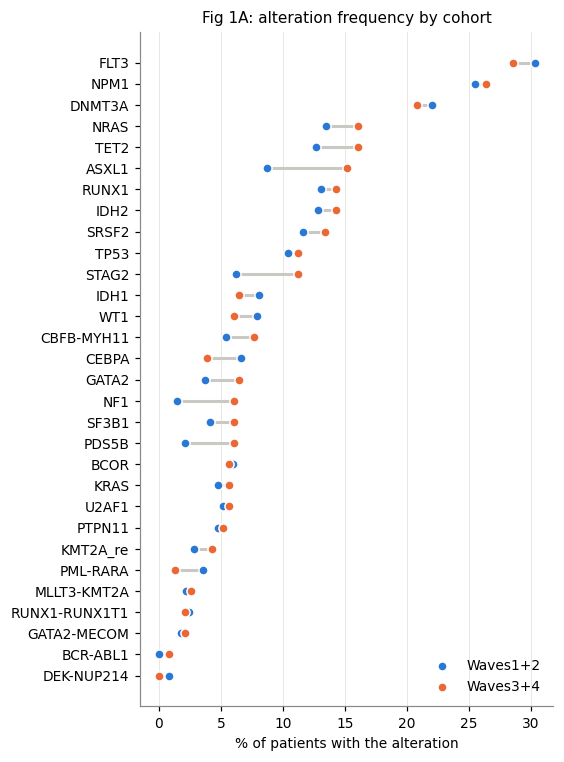

In [7]:
fus_tr = FUS[FUS.cohort.eq("Waves1+2")].drop(columns="cohort"); fus_te = FUS[FUS.cohort.eq("Waves3+4")].drop(columns="cohort")
freq = pd.DataFrame({
    "Waves1+2": pd.concat([MUT_tr.rename(columns={"FLT3_ITD": "FLT3"}).T.groupby(level=0).max().T.mean(), fus_tr.mean()]),
    "Waves3+4": pd.concat([MUT_te.rename(columns={"FLT3_ITD": "FLT3"}).T.groupby(level=0).max().T.mean(), fus_te.mean()]),
})
is_fus = freq.index.isin(fus_tr.columns)
freq = freq[(freq.max(axis=1) > 0.05) | is_fus].fillna(0)
freq = freq.loc[freq.max(axis=1).sort_values().index]
freq["diff"] = freq["Waves3+4"] - freq["Waves1+2"]
print(f"genes/fusions shown: {len(freq)} | mean difference (Waves3+4 - Waves1+2): {100*freq['diff'].mean():.3f} percentage points (paper: 1.037)")

fig, ax = plt.subplots(figsize=(5.2, 7))
y = np.arange(len(freq))
ax.hlines(y, freq["Waves1+2"] * 100, freq["Waves3+4"] * 100, color="#c9c8c2", lw=2)
for c in WAVE_COL:
    ax.scatter(freq[c] * 100, y, s=36, color=WAVE_COL[c], label=c, zorder=3, edgecolor="white", linewidth=1)
ax.set_yticks(y, freq.index); ax.set_xlabel("% of patients with the alteration"); ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="lower right"); ax.set_title("Fig 1A: alteration frequency by cohort")
plt.tight_layout(); plt.show()

**Interpretation.** The two dots for each gene sit close together. Large differences would point to a change in patient mix
or sequencing method. ASXL1 shows one of the bigger gaps (8.7% → 15.2%, the same values the authors' code reports). The mean
difference (1.035) is within 0.002 percentage points of the paper's 1.037, so the mutation matrix is built the same way.

### Fig 1B: overall survival per cohort
**Method: Kaplan–Meier + log-rank.** Survival data are pairs (time, event). *Event* = died. A patient still alive at last
contact is **censored**: we only know they lived *at least* that long. Dropping censored patients would bias survival
downward, and treating their time as a death would too. The **Kaplan–Meier** estimator handles this: at each death time,
survival is multiplied by (1 − deaths / patients still at risk). The **log-rank test** compares observed vs expected deaths in
each group at every death time. Its χ² statistic (1 degree of freedom for two groups) gives the p-value.

**Inputs.** One specimen per patient (the earliest), patients with known survival. Paper: χ² = 1.3, p = 0.2.

de novo fraction by cohort (paper: 49% vs 58%): {'Waves1+2': '49.3%', 'Waves3+4': '58.1%'}
            N deaths
cohort              
Waves1+2  491    310
Waves3+4  214    120
log-rank chi2 = 1.32, p = 0.25   (paper: chi2 = 1.3, p = 0.2)


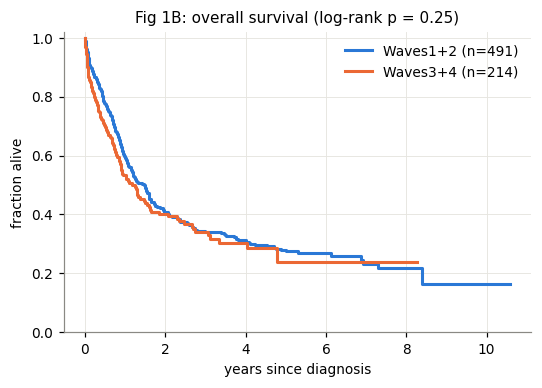

In [8]:
first = clin.sort_values("timeOfSampleCollectionRelativeToInclusion").groupby("dbgap_subject_id").head(1)
print("de novo fraction by cohort (paper: 49% vs 58%):",
      first.groupby("cohort").isDenovo.apply(lambda s: f"{s.eq('TRUE').mean():.1%}").to_dict())
surv1 = first[first.is_dead.notna() & first.overallSurvival.notna()]
a, b = (surv1[surv1.cohort.eq(c)] for c in WAVE_COL)
lr = logrank_test(a.overallSurvival, b.overallSurvival, a.is_dead.astype(bool), b.is_dead.astype(bool))
print(surv1.groupby("cohort").agg(N=("is_dead", "size"), deaths=("is_dead", "sum")).to_string())
print(f"log-rank chi2 = {lr.test_statistic:.2f}, p = {lr.p_value:.2f}   (paper: chi2 = 1.3, p = 0.2)")

fig, ax = plt.subplots(figsize=(5, 3.6))
for c, d in ((c, surv1[surv1.cohort.eq(c)]) for c in WAVE_COL):
    KaplanMeierFitter(label=f"{c} (n={len(d)})").fit(d.overallSurvival / 365.25, d.is_dead.astype(bool)) \
        .plot_survival_function(ax=ax, color=WAVE_COL[c], ci_show=False, lw=2)
ax.set_xlabel("years since diagnosis"); ax.set_ylabel("fraction alive"); ax.set_ylim(0, 1.02)
ax.legend(frameon=False); ax.set_title(f"Fig 1B: overall survival (log-rank p = {lr.p_value:.2f})")
plt.tight_layout(); plt.show()

**Interpretation.** The curves overlap and p = 0.25 (R prints this as "0.2"), so there's no evidence that survival differs
between cohorts. The patient and death counts (491/310 and 214/120) are identical to the authors' `survdiff` output, and the
de novo fractions (49% vs 58%) match the paper's text.

### Fig 1C: average drug response in de novo patients
**Method.** For each drug screened in both cohorts (`status == "train/test"`), take the mean AUC across de novo patients in each
cohort, then correlate the two vectors of means (Pearson r). Only de novo cases are used because secondary AML is generally less
drug-sensitive, and the cohorts differ slightly in their secondary AML fraction. Paper: **r = 0.965**.

95 drugs | Pearson r = 0.9653 (paper 0.9652), p = 4.9e-56


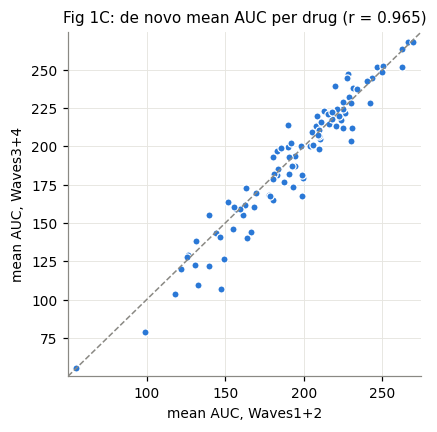

In [9]:
tt = inh[inh.status.eq("train/test")]
mean_auc = tt[tt.isDenovo.eq("TRUE")].groupby(["inhibitor", "cohort"]).auc.mean().unstack()
r, p = stats.pearsonr(mean_auc["Waves1+2"], mean_auc["Waves3+4"])
print(f"{len(mean_auc)} drugs | Pearson r = {r:.4f} (paper 0.9652), p = {p:.1e}")

fig, ax = plt.subplots(figsize=(4, 4))
ax.scatter(mean_auc["Waves1+2"], mean_auc["Waves3+4"], s=22, color=WAVE_COL["Waves1+2"], edgecolor="white", linewidth=0.8)
lims = [mean_auc.min().min() - 5, mean_auc.max().max() + 5]
ax.plot(lims, lims, ls="--", color=MUTED, lw=1); ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_xlabel("mean AUC, Waves1+2"); ax.set_ylabel("mean AUC, Waves3+4")
ax.set_title(f"Fig 1C: de novo mean AUC per drug (r = {r:.3f})"); plt.tight_layout(); plt.show()

**Interpretation.** Each dot is a drug, and they hug the diagonal: a drug that is potent on average in the old cohort is potent
in the new one too. So the assay behaved consistently across the two collection periods. The fourth-decimal difference from the
paper (0.9653 vs 0.9652) is floating-point noise.

### Fig 1D: do mutation–drug associations replicate?
**Method.** This is the key validation. For every (mutated gene, drug) pair, run a Welch t-test of AUC (mutated vs wild-type)
**separately in each cohort**:

* Waves 1+2 require ≥ 5 mutated patients and Waves 3+4 require ≥ 3, roughly matching the 5:3 cohort-size ratio.
* Each cohort's p-values become Storey q-values.
* **Concordance** = among associations significant in Waves 1+2 (q < 0.05), the fraction whose effect has the **same sign**
  in Waves 3+4. The paper reports **213 / 239 = 89%**.

Why sign agreement instead of significance in both? The new cohort is smaller, so many true effects won't reach significance
there. But a true effect should at least point the same way. Under pure chance, ~50% would agree.

tests run in both cohorts: 2,526 | pi0 estimates: 0.70, 0.84
significant in Waves1+2: 239 | same direction in Waves3+4: 213 -> 89.1%  (paper: 213/239 = 89%)


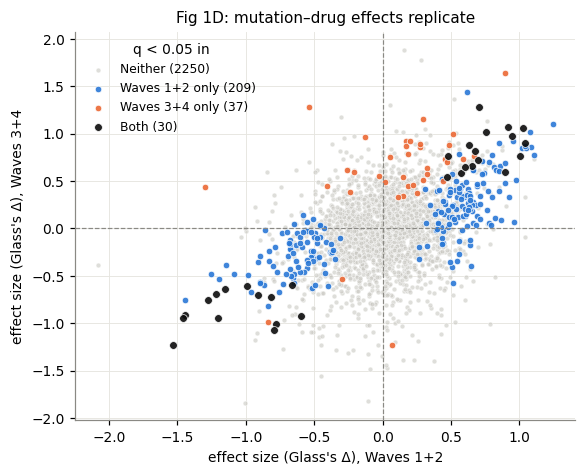

Strongest replicated associations (negative = mutated cells are MORE sensitive):
    gene                   outcome  n_mut_12  glass_d_12  glass_d_34   q_12   q_34
FLT3_ITD         Foretinib (XL880)        63     -1.1529     -0.6385 0.0000 0.0318
FLT3_ITD                 Sunitinib        65     -1.4619     -0.9452 0.0000 0.0011
FLT3_ITD              Cabozantinib        64     -1.2787     -0.7588 0.0000 0.0260
FLT3_ITD                   KW-2449        63     -1.4439     -0.9115 0.0000 0.0126
FLT3_ITD      Dovitinib (CHIR-258)        63     -1.2152     -0.6906 0.0000 0.0259
FLT3_ITD                 Sorafenib        66     -1.5328     -1.2279 0.0000 0.0001
FLT3_ITD     17-AAG (Tanespimycin)        64     -0.9895     -0.6069 0.0000 0.0321
FLT3_ITD Regorafenib (BAY 73-4506)        63     -0.9072     -0.7042 0.0000 0.0321
    KRAS                   KW-2449        12      1.0387      0.9059 0.0000 0.0293
FLT3_ITD       Linifanib (ABT-869)        63     -0.8164     -0.7274 0.0001 0.0321


In [10]:
A_tt = tt.pivot_table(index="ptid", columns="inhibitor", values="auc")        # patients x drugs
w12 = welch_assoc(MUT_tr, A_tt, min_muts=5)
w34 = welch_assoc(MUT_te, A_tt, min_muts=3)
tt_assoc = w12.merge(w34, on=["gene", "outcome"], suffixes=("_12", "_34"))
tt_assoc["q_12"], pi0_12 = qvalue(tt_assoc.pval_12)
tt_assoc["q_34"], pi0_34 = qvalue(tt_assoc.pval_34)
sig12 = tt_assoc[tt_assoc.q_12 < 0.05]
agree = (np.sign(sig12.estimate_12) == np.sign(sig12.estimate_34)).sum()
print(f"tests run in both cohorts: {len(tt_assoc):,} | pi0 estimates: {pi0_12:.2f}, {pi0_34:.2f}")
print(f"significant in Waves1+2: {len(sig12)} | same direction in Waves3+4: {agree} -> {agree/len(sig12):.1%}  (paper: 213/239 = 89%)")

cat = np.select([(tt_assoc.q_12 < .05) & (tt_assoc.q_34 < .05), tt_assoc.q_12 < .05, tt_assoc.q_34 < .05],
                ["Both", "Waves 1+2 only", "Waves 3+4 only"], "Neither")
style = {"Neither": ("#c9c8c2", 10), "Waves 1+2 only": (WAVE_COL["Waves1+2"], 18),
         "Waves 3+4 only": (WAVE_COL["Waves3+4"], 18), "Both": (INK, 26)}
fig, ax = plt.subplots(figsize=(5.4, 4.4))
for k, (col, s) in style.items():
    sel = cat == k
    ax.scatter(tt_assoc.glass_d_12[sel], tt_assoc.glass_d_34[sel], s=s, color=col, label=f"{k} ({sel.sum()})",
               edgecolor="white", linewidth=0.5, alpha=0.9 if k != "Neither" else 0.6)
ax.axhline(0, ls="--", color=MUTED, lw=0.8); ax.axvline(0, ls="--", color=MUTED, lw=0.8)
ax.set_xlabel("effect size (Glass's Δ), Waves 1+2"); ax.set_ylabel("effect size (Glass's Δ), Waves 3+4")
ax.legend(title="q < 0.05 in", frameon=False, fontsize=8); ax.set_title("Fig 1D: mutation–drug effects replicate")
plt.tight_layout(); plt.show()

print("Strongest replicated associations (negative = mutated cells are MORE sensitive):")
print(tt_assoc[cat == "Both"].sort_values("pval_12")[["gene", "outcome", "n_mut_12", "glass_d_12", "glass_d_34", "q_12", "q_34"]]
      .head(10).round(4).to_string(index=False))

**Interpretation.** Exactly **213 of 239 (89%)**, the same as the paper. Points fall mostly in the bottom-left and top-right
quadrants, where the effect has the same sign in both cohorts. The strongest replicated hits are expected biology, such as
FLT3-ITD making cells more sensitive (negative Δ) to FLT3 inhibitors. This establishes that the two cohorts can be pooled,
which the rest of the paper does.

---
## Part 2: Tumor maturation state, the PC1 cell-type scores (Figure 2, S2)

**The question.** AML tumors are frozen at different points along normal blood-cell development, from stem-cell-like (HSC) to
mature monocyte- or dendritic-cell-like. van Galen et al. (2019) used **single-cell** RNA-seq to define 6 malignant cell types
along this axis:

`HSC-like → Progenitor-like → GMP-like → Promono-like → Monocyte-like → cDC-like`
(least mature → most mature)

Beat AML has **bulk** RNA-seq: one expression profile per patient, mixing all of its cells. The authors want one number per
patient per cell type, saying "how much of this cell type's program is switched on in this tumor".

**Method: PC1 scoring (PLAGE-style), step by step.** These are the steps in `paper_score()` in
`scripts/replication_vangalen_scores.py`.

1. **Gene set.** Take the top 30 marker genes for the cell type from van Galen Table S3 (a few aren't in the expression matrix,
   so 24–30 are used).
2. **Center and scale per tissue.** Z-score each gene, separately for bone marrow and for blood/leukapheresis samples. Blood
   and marrow have different baseline cell mixes. Without this step, the first thing PC1 would capture is "is this a blood
   sample?" rather than tumor biology.
3. **PCA on the Waves 1+2 samples.** PC1 is the weighted combination of the 30 genes that varies most across patients. When
   genes in a set are co-expressed, PC1 is essentially their shared "on/off" signal. The **score** is each patient's
   coordinate on PC1.
4. **Fix the sign.** PCA's sign is arbitrary. Flip it if needed so a high score means the genes are high on average.
5. **Project Waves 3+4.** Apply the *Waves 1+2* means, SDs, and gene weights to the new patients. Nothing is refit, so
   the new cohort can't influence the definition of the score (no "leakage").

Steps 2–5 are the same as how WGCNA summarizes a gene module into an **eigengene**, which is why the paper calls these "similar
to the WGCNA eigengene".

In [11]:
sigs = load_signatures()                                    # {cell type: 30 genes} from van Galen Table S3
CT = {}
for ct in CELL_TYPES:
    genes = [g for g in sigs[ct] if g in X.columns]
    CT[ct] = paper_score(X[genes].to_numpy(float), tissue_bm=is_bm, train=is_train)
    print(f"{ct:<16} {len(genes)}/30 genes in the expression matrix")
CT = pd.DataFrame(CT, index=X.index)

# Check against the scores the authors published (beataml2_manuscript_vg_cts.xlsx)
pub = load_pc1_baseline().reindex(rna_clin.dbgap_rnaseq_sample).set_axis(X.index)
check = pd.DataFrame({"r with published": [np.corrcoef(CT[c], pub[c])[0, 1] for c in CELL_TYPES],
                      "max |difference|": [np.abs(CT[c] - pub[c]).max() for c in CELL_TYPES]}, index=CELL_TYPES)
check.round(6)

HSC-like         28/30 genes in the expression matrix
Progenitor-like  25/30 genes in the expression matrix
GMP-like         24/30 genes in the expression matrix
Promono-like     30/30 genes in the expression matrix
Monocyte-like    29/30 genes in the expression matrix
cDC-like         29/30 genes in the expression matrix


,r with published,max |difference|
HSC-like,1.0,0.0
Progenitor-like,1.0,0.0
GMP-like,1.0,0.0
Promono-like,1.0,0.0
Monocyte-like,1.0,0.0
cDC-like,1.0,0.0


**Interpretation.** Correlation 1.0 and a max difference of 0 for every cell type, on all 560 patients: the scoring code
reproduces the published scores **exactly**. So every downstream analysis can use them with confidence.

### What PC1 is doing: a worked example (cf. Fig S2A)
The heatmap shows the z-scored expression of the Monocyte-like genes, with patients sorted by their Monocyte-like score. If
PC1 is a good summary, the genes should shift together from low (red) on the left to high (blue) on the right. The bottom
panel is the score itself.

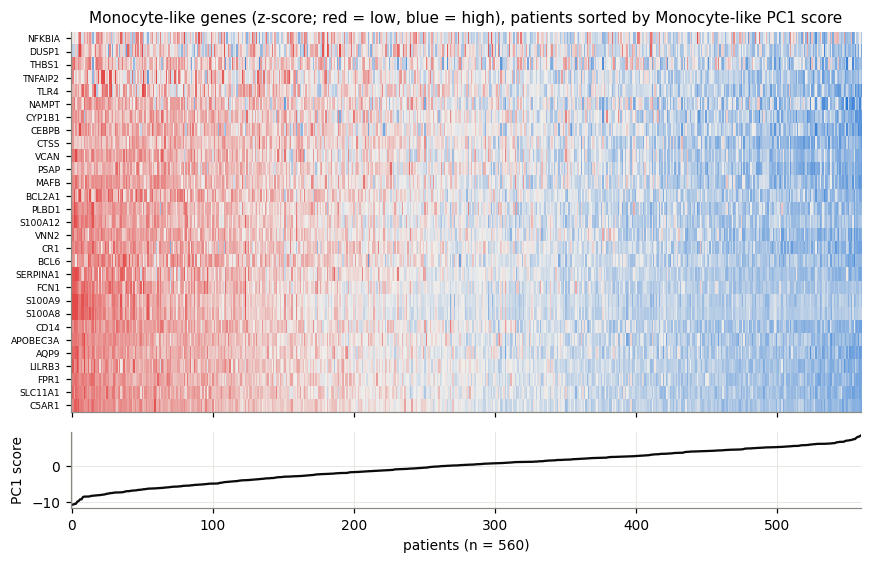

HSC-like         PC1 explains 24% of the variance in its 28 genes
Progenitor-like  PC1 explains 37% of the variance in its 25 genes
GMP-like         PC1 explains 28% of the variance in its 24 genes
Promono-like     PC1 explains 32% of the variance in its 30 genes
Monocyte-like    PC1 explains 64% of the variance in its 29 genes
cDC-like         PC1 explains 36% of the variance in its 29 genes


In [12]:
ct = "Monocyte-like"
genes = [g for g in sigs[ct] if g in X.columns]
Z = X[genes].copy()
for grp in (is_bm, ~is_bm):                                     # per-tissue z-score using Waves1+2 parameters, as in step 2
    mu, sd = Z[grp & is_train].mean(), Z[grp & is_train].std(ddof=1)
    Z[grp] = (Z[grp] - mu) / sd
order = CT[ct].sort_values().index
gene_order = Z.corrwith(CT[ct]).sort_values().index

fig, (a1, a2) = plt.subplots(2, 1, figsize=(8, 5.2), height_ratios=[5, 1], sharex=True)
a1.imshow(Z.loc[order, gene_order].T.clip(-3, 3), aspect="auto", cmap=DIV, vmin=-3, vmax=3, interpolation="nearest")
a1.set_yticks(range(len(gene_order)), gene_order, fontsize=6); a1.grid(False)
a1.set_title(f"{ct} genes (z-score; red = low, blue = high), patients sorted by {ct} PC1 score")
a2.plot(np.arange(len(order)), CT.loc[order, ct], color=INK, lw=1.5); a2.set_ylabel("PC1 score")
a2.set_xlabel("patients (n = 560)"); plt.tight_layout(); plt.show()

# How much of the gene-set variance does PC1 capture?
for ct_ in CELL_TYPES:
    g_ = [g for g in sigs[ct_] if g in X.columns]
    Zt = X.loc[is_train, g_].copy()
    for grp in (is_bm[is_train], ~is_bm[is_train]):
        Zt[grp] = (Zt[grp] - Zt[grp].mean()) / Zt[grp].std(ddof=1)
    s = np.linalg.svd(Zt.to_numpy(), compute_uv=False)
    print(f"{ct_:<16} PC1 explains {s[0]**2 / (s**2).sum():.0%} of the variance in its {len(g_)} genes")

**Interpretation.** Most monocyte genes move together, so one number captures much of the signal. The printed "variance
explained" says how good a summary PC1 is for each set. Monocyte-like is strong (64%). HSC-like and GMP-like
are weak (about a quarter): their marker genes are less coherent in bulk data, so those scores are noisier proxies. That's a known limitation of the baseline and part of the motivation
for learned latent features.

### Sanity check against morphology: Fig S2B
**Method.** FAB subtype is the old microscope-based classification. M0–M2 are immature (myeloblastic), and M4–M5 are
monocytic. If the scores capture maturation, HSC-like should be highest in M0–M2 and Monocyte-like highest in M4–M5.

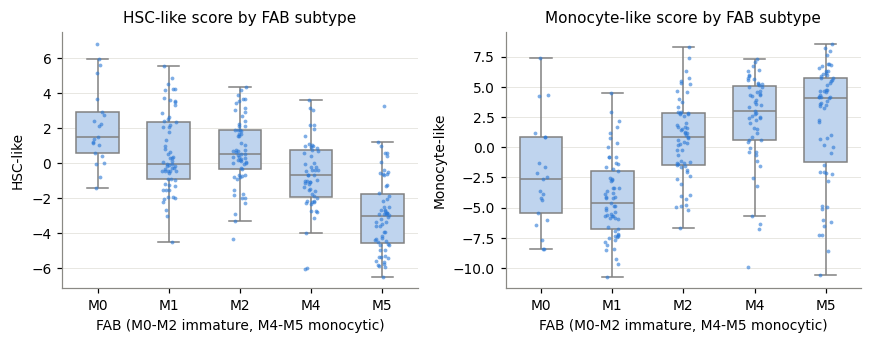

FAB              M0    M1    M2    M4    M5
HSC-like       1.51 -0.05  0.53 -0.69 -3.01
Monocyte-like -2.64 -4.61  0.88  3.03  4.09


In [13]:
fab = rna_clin.fabBlastMorphology.astype(str).str.extract(r"^(M[0-7])")[0]
fab = fab.where(~rna_clin.fabBlastMorphology.astype(str).str.contains("/"))   # drop ambiguous "M0/M1"
dfab = CT.join(fab.rename("FAB")).dropna(subset=["FAB"])
dfab = dfab[dfab.FAB.isin(["M0", "M1", "M2", "M4", "M5"])]
fig, axes = plt.subplots(1, 2, figsize=(8, 3.2), sharey=False)
for ax, c in zip(axes, ["HSC-like", "Monocyte-like"]):
    sns.boxplot(data=dfab, x="FAB", y=c, order=["M0", "M1", "M2", "M4", "M5"], ax=ax, color="#b7d3f6", fliersize=0, width=0.6)
    sns.stripplot(data=dfab, x="FAB", y=c, order=["M0", "M1", "M2", "M4", "M5"], ax=ax, color=WAVE_COL["Waves1+2"], size=2.5, alpha=0.6)
    ax.set_title(f"{c} score by FAB subtype"); ax.set_xlabel("FAB (M0-M2 immature, M4-M5 monocytic)")
plt.tight_layout(); plt.show()
print(dfab.groupby("FAB")[["HSC-like", "Monocyte-like"]].median().round(2).T)

**Interpretation.** HSC-like is highest in M0 and lowest in M5. Monocyte-like is lowest in M0–M1 and highest in M4–M5. The
trend isn't perfectly monotone (FAB is a coarse, subjective call), but the direction matches the paper's Fig S2B, so the scores
track the biology they claim to measure.

### WGCNA module eigengenes (needed for Fig 2A and Part 5)
**Background.** In 2018 the authors grouped genes into **co-expression modules** with WGCNA. A module is a set of genes whose
expression rises and falls together across patients (13 real modules plus M0, the "grey" leftovers). Each module is summarized
by its **eigengene**: the PC1 of its genes, computed exactly as above but with **one** global z-scoring instead of per-tissue
scaling (`predict.modules()` in the R code). We reuse `paper_score()` and pass a tissue mask that puts every sample in one group.

In [14]:
wg = load_wgcna_modules()                       # gene -> module, from data/interim/wgcna_cur_map.csv
one_group = np.ones(len(X), dtype=bool)         # global scaling: everyone in a single "tissue" group
ME = {m: paper_score(X[g.display_label.tolist()].to_numpy(float), tissue_bm=one_group, train=is_train)
      for m, g in wg.groupby("cur_labels") if m != "M0"}
ME = pd.DataFrame(ME, index=X.index)[sorted(ME, key=lambda m: int(m[1:]))]
print("module sizes:", wg[wg.cur_labels != "M0"].cur_labels.value_counts().reindex(ME.columns).to_dict())

module sizes: {'M1': 310, 'M3': 203, 'M4': 198, 'M6': 159, 'M7': 154, 'M8': 139, 'M9': 119, 'M11': 112, 'M12': 97, 'M14': 88, 'M16': 85, 'M21': 71, 'M23': 53}


### Fig 2A: how do co-expression modules relate to cell types?
**Method.** Pearson correlation between each module eigengene and each cell-type score, across all 560 patients.

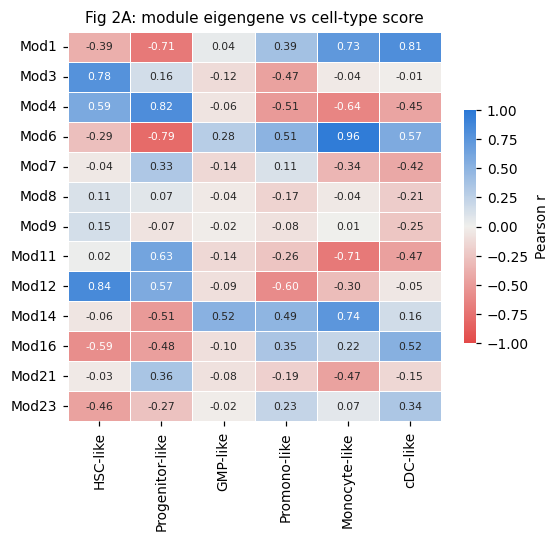

In [15]:
R_me_ct = pd.DataFrame({ct: ME.corrwith(CT[ct]) for ct in CELL_TYPES})
fig, ax = plt.subplots(figsize=(5.2, 5))
sns.heatmap(R_me_ct.rename(index=lambda m: m.replace("M", "Mod")), cmap=DIV, vmin=-1, vmax=1, annot=True, fmt=".2f",
            annot_kws={"size": 7}, linewidths=0.5, linecolor="white", cbar_kws={"label": "Pearson r", "shrink": 0.6}, ax=ax)
ax.set_title("Fig 2A: module eigengene vs cell-type score"); ax.set_xlabel(""); ax.set_ylabel(""); ax.grid(False)
plt.tight_layout(); plt.show()

**Interpretation.** Several modules are basically cell-type programs. For example Mod6 correlates r ≈ 0.96 with Monocyte-like,
and Mod12 and Mod3 correlate with HSC-like. Some modules are **both** strongly positive with one end of the maturation axis and
strongly negative with the other (Mod1, Mod4, Mod6, Mod11). These are redundant with the cell-type scores, so for the combined
feature set the authors drop any module with |r| > 0.6 of **both** signs (`mutation.expression.features()`). We get the same
four removals, which leaves **9 non-redundant modules**, the number the paper reports for Fig 6A.

### Building the combined feature table
This table feeds Figs 2B, 3B, 5B, 6 and 7:
* 9 module eigengenes + 6 cell-type scores (continuous)
* fusions with ≥ 10 carriers, and genes mutated in ≥ 10 Waves 1+2 patients (0/1)

In [16]:
redundant = [m for m in ME.columns
             if len(set(np.sign(R_me_ct.loc[m][R_me_ct.loc[m].abs() > 0.6]))) > 1]
print("modules removed as redundant with cell types:", redundant)

fus_feat = FUS.drop(columns="cohort"); fus_feat = fus_feat.loc[:, fus_feat.sum() >= 10]
mut_genes = [g for g in MUT_tr.columns if MUT_tr[g].sum() >= 10 and g in MUT_te.columns]
feat = (ME.drop(columns=redundant).join(CT)
          .join(fus_feat.add_prefix("fus."), how="outer")
          .join(MUT[mut_genes].add_prefix("mut."), how="outer"))
ALT = [c for c in feat.columns if c.startswith(("mut.", "fus."))]          # binary alteration features
MODS = [c for c in ME.columns if c not in redundant]
print(f"feature table: {feat.shape[0]} patients x {feat.shape[1]} features "
      f"({len(MODS)} modules, {len(CELL_TYPES)} cell types, {len(ALT)} mutations/fusions)")
print("alterations:", ", ".join(a.split(".", 1)[1] for a in ALT))

modules removed as redundant with cell types: ['M1', 'M4', 'M6', 'M11']


feature table: 735 patients x 48 features (9 modules, 6 cell types, 33 mutations/fusions)
alterations: CBFB-MYH11, GATA2-MECOM, KMT2A_re, MLLT3-KMT2A, PML-RARA, RUNX1-RUNX1T1, ASXL1, BCOR, BCORL1, CEBPA, DNMT3A, EZH2, FLT3, GATA2, IDH1, IDH2, JAK2, KRAS, NPM1, NRAS, PDS5B, PHF6, PTPN11, RAD21, RUNX1, SF3B1, SRSF2, STAG2, TET2, TP53, U2AF1, WT1, FLT3_ITD


### Fig 2B: which mutations go with which maturation state?
**Method.** Welch t-test of each cell-type score between mutated and wild-type patients (≥ 5 mutated), on patients with both RNA
and DNA data, then Storey q-values. The plot shows **signed −log10(p)**: up = the mutation is associated with a *higher* score
for that cell type. A taller bar means stronger evidence.

patients: 539 | tests: 198 | significant (q<0.05): 80


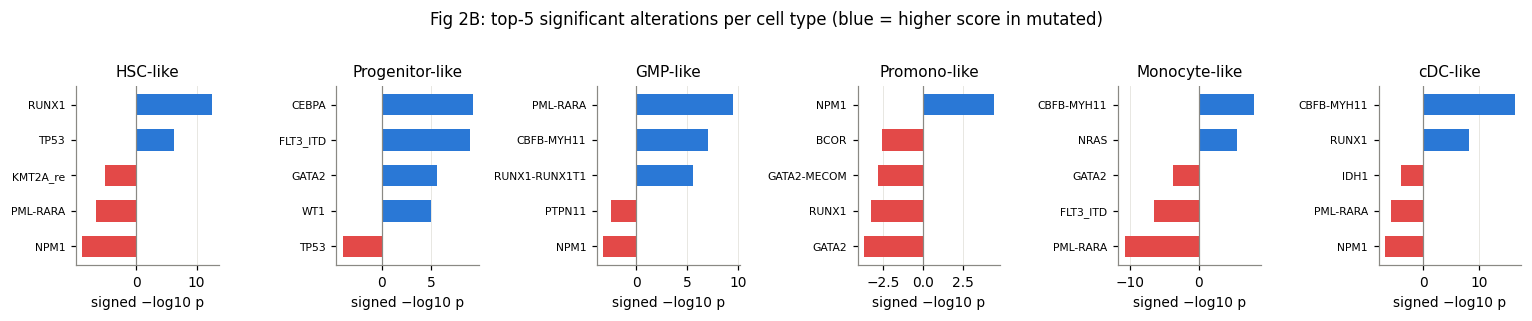

In [17]:
fc = feat[ALT + CELL_TYPES].dropna()
ct_mut = welch_assoc(fc[ALT], fc[CELL_TYPES], min_muts=5)
ct_mut["q"], _ = qvalue(ct_mut.pval)
ct_mut["signed_logp"] = np.sign(ct_mut.estimate) * -np.log10(ct_mut.pval)
print(f"patients: {len(fc)} | tests: {len(ct_mut)} | significant (q<0.05): {(ct_mut.q < 0.05).sum()}")

fig, axes = plt.subplots(1, 6, figsize=(14, 2.8))
for ax, c in zip(axes, CELL_TYPES):
    d = ct_mut[(ct_mut.outcome == c) & (ct_mut.q < 0.05)].sort_values("pval").head(5).sort_values("signed_logp")
    ax.barh(d.gene.str.split(".", n=1).str[1], d.signed_logp, height=0.6,
            color=np.where(d.signed_logp > 0, "#2a78d6", "#e34948"))
    ax.axvline(0, color=MUTED, lw=0.8); ax.set_title(c); ax.set_xlabel("signed −log10 p")
    ax.tick_params(axis="y", labelsize=7); ax.grid(axis="y", visible=False)
fig.suptitle("Fig 2B: top-5 significant alterations per cell type (blue = higher score in mutated)", y=1.02)
plt.tight_layout(); plt.show()

In [18]:
# The specific associations named in the paper's text
named = [("mut.TP53", "HSC-like"), ("mut.BCOR", "HSC-like"), ("mut.SF3B1", "HSC-like"), ("mut.NPM1", "Promono-like"),
         ("mut.NRAS", "Monocyte-like"), ("mut.KRAS", "Monocyte-like"), ("mut.RUNX1", "HSC-like"), ("mut.RUNX1", "cDC-like")]
ct_mut.set_index(["gene", "outcome"]).loc[named, ["n_mut", "estimate", "pval", "q"]].round(5)

n_mut  estimate     pval        q
gene      outcome                                         
mut.TP53  HSC-like          54   1.70042  0.00000  0.00000
mut.BCOR  HSC-like          31   1.90427  0.00020  0.00051
mut.SF3B1 HSC-like          26   1.77363  0.00081  0.00164
mut.NPM1  Promono-like     142   1.15831  0.00003  0.00012
mut.NRAS  Monocyte-like     85   2.33987  0.00000  0.00001
mut.KRAS  Monocyte-like     29   2.55304  0.00060  0.00136
mut.RUNX1 HSC-like          68   2.35763  0.00000  0.00000
          cDC-like          68   1.99096  0.00000  0.00000

**Interpretation.** These match the paper's text. TP53, BCOR and SF3B1 mutant tumors are more stem-like (HSC-like up). NPM1
mutant tumors are more promonocytic. RAS mutations go with monocytic tumors. RUNX1 is the interesting one: it is **positive for
both** the least mature (HSC-like) and the most mature (cDC-like) programs. The paper reads this as RUNX1-mutant tumors mixing
features of disparate maturation states. Fusions such as CBFB-MYH11 (cDC/monocytic) and PML-RARA (GMP/promyelocytic) show the
largest shifts, as expected from their known morphology.

---
## Part 3: Does maturation state shape drug response? (Figure 3, S3)

### Fig 3A: drug AUC vs cell-type score
**The question.** Clinicians know venetoclax works best in immature AML and that monocytic AML resists it. How general is this?
Is drug response tied to maturation state for many drugs?

**Inputs.** Patients with both RNA-seq and a drug screen. Drugs with `status` "train/test" or "combined".

**Method.**
* Pearson correlation of AUC with each cell-type score, for each drug: 6 cell types × ~120 drugs ≈ 740 tests.
* **Multiple testing: Benjamini–Yekutieli (BY) FDR.** BH assumes the tests are independent or positively dependent. Here they
  are not: the six scores are correlated with each other, and so are drugs with shared targets. BY is valid under *any*
  dependence, at the cost of being more conservative. The authors' code comments: *"as the p-values seem to indicate a little
  too much dependency."*
* A drug counts if it is significant (BY FDR < 0.05) for at least one cell type. Paper: **73 drugs**.

**Reading the sign.** AUC up = more resistant. So a **negative** r (red) means patients with *more* of that cell type are
*more sensitive*, and a positive r (blue) means more resistant.

In [19]:
inh_used = inh[inh.status.isin(["train/test", "combined"])]
A = inh_used.pivot_table(index="ptid", columns="inhibitor", values="auc")     # patients x drugs, NaN = not tested
rows = []
for d in A.columns:
    y = A[d].reindex(CT.index); ok = y.notna()
    for c in CELL_TYPES:
        r, p = stats.pearsonr(CT.loc[ok, c], y[ok])
        rows.append(dict(inhibitor=d, cell_type=c, r=r, p=p, n=int(ok.sum())))
drug_ct = pd.DataFrame(rows)
drug_ct["fdr_BY"] = multipletests(drug_ct.p, method="fdr_by")[1]
drug_ct["fdr_BH"] = multipletests(drug_ct.p, method="fdr_bh")[1]
sig_drugs = drug_ct.loc[drug_ct.fdr_BY < 0.05, "inhibitor"].unique()
print(f"drugs tested: {drug_ct.inhibitor.nunique()} | patients per drug: {drug_ct.n.min()}-{drug_ct.n.max()}")
print(f"drugs significant for >=1 cell type (BY FDR < 0.05): {len(sig_drugs)}   (paper: 73)")
print(f"  ...for comparison, with the less conservative BH FDR it would be {drug_ct.loc[drug_ct.fdr_BH < .05, 'inhibitor'].nunique()}")

drugs tested: 123 | patients per drug: 103-421
drugs significant for >=1 cell type (BY FDR < 0.05): 73   (paper: 73)
  ...for comparison, with the less conservative BH FDR it would be 93


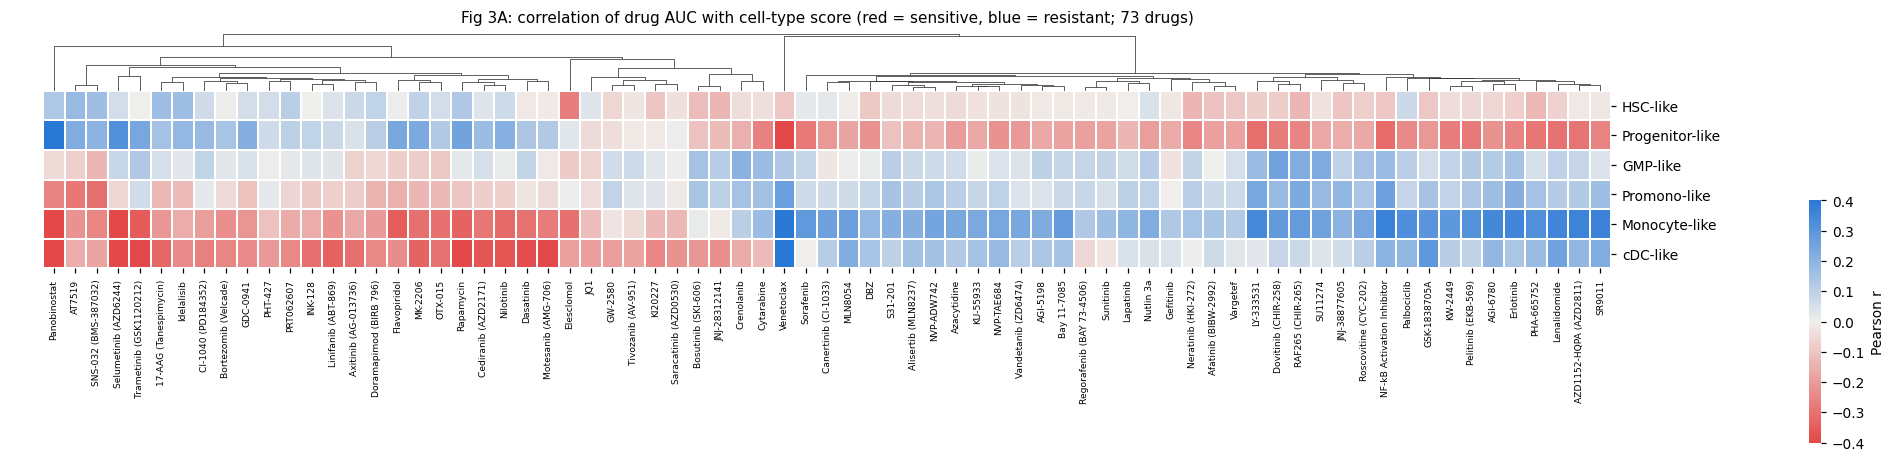

In [20]:
M = drug_ct[drug_ct.inhibitor.isin(sig_drugs)].pivot(index="cell_type", columns="inhibitor", values="r").loc[CELL_TYPES]
g = sns.clustermap(M, row_cluster=False, col_cluster=True, method="average", cmap=DIV, vmin=-0.4, vmax=0.4,
                   figsize=(16, 4.4), linewidths=0.3, linecolor="white", dendrogram_ratio=(0.02, 0.25), cbar_pos=(1.03, 0.12, 0.007, 0.5),
                   cbar_kws={"label": "Pearson r"}, xticklabels=True)
g.ax_heatmap.grid(False)
g.ax_heatmap.tick_params(axis="x", labelsize=6); g.ax_heatmap.set_xlabel(""); g.ax_heatmap.set_ylabel("")
g.ax_col_dendrogram.set_title("Fig 3A: correlation of drug AUC with cell-type score (red = sensitive, blue = resistant; 73 drugs)")
plt.show()

**Interpretation.** Exactly **73 drugs**, as in the paper. Average-linkage clustering of the drugs (columns) gives the paper's
three patterns:
1. **Red at the top (immature rows), blue at the bottom (mature rows)**: drugs that work better on *immature*
   (progenitor-like) tumors and worse on monocytic ones, e.g. venetoclax (r = −0.54 with Progenitor-like, +0.73 with
   Monocyte-like) and the CDK4/6 inhibitor palbociclib.
2. **The mirror image**: drugs that work better on *mature* (monocyte/cDC-like) tumors, e.g. the MEK inhibitors trametinib and
   selumetinib, and panobinostat.
3. A smaller group most resistant in the GMP/promonocyte middle.

The practical point is that **maturation state is a confounder**. If a mutation is enriched in monocytic tumors (like RAS), and a
drug works on monocytic tumors, the mutation will look associated with the drug even if it isn't the cause. Notice too that
BY vs BH changes the count, so "73" depends on the multiple-testing choice.

### Fig S3A: the two extreme outliers
Venetoclax and panobinostat have the strongest Monocyte-like correlations, in opposite directions.

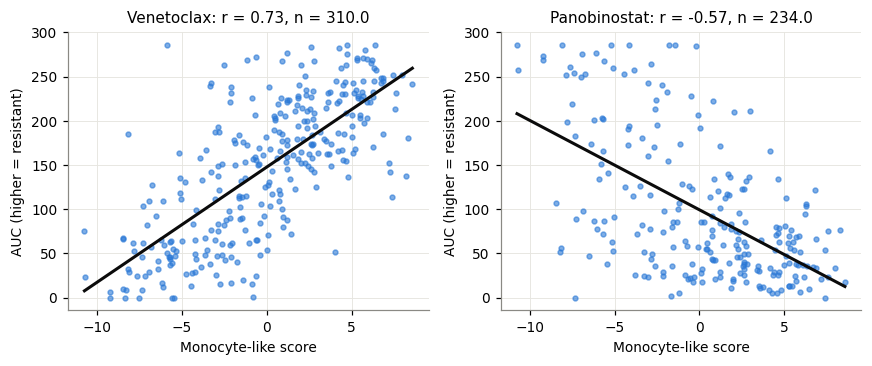

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3.4))
for ax, d in zip(axes, ["Venetoclax", "Panobinostat"]):
    y = A[d].reindex(CT.index); ok = y.notna()
    r_ = drug_ct.set_index(["inhibitor", "cell_type"]).loc[(d, "Monocyte-like")]
    ax.scatter(CT.loc[ok, "Monocyte-like"], y[ok], s=10, color=WAVE_COL["Waves1+2"], alpha=0.6)
    b1, b0 = np.polyfit(CT.loc[ok, "Monocyte-like"], y[ok], 1); xs = np.linspace(CT["Monocyte-like"].min(), CT["Monocyte-like"].max(), 2)
    ax.plot(xs, b0 + b1 * xs, color=INK, lw=2)
    ax.set_title(f"{d}: r = {r_.r:.2f}, n = {r_.n}"); ax.set_xlabel("Monocyte-like score"); ax.set_ylabel("AUC (higher = resistant)")
plt.tight_layout(); plt.show()

**Interpretation.** Venetoclax AUC climbs with Monocyte-like score, so monocytic tumors resist it. This matches clinical
experience of venetoclax resistance in monocytic AML. Panobinostat (HDAC inhibitor) shows the opposite pattern.

### Fig 3B: is a mutation's effect on a drug *conditional* on cell type?
**The question.** Does FLT3-ITD sensitize cells to a FLT3 inhibitor equally in immature and mature tumors?

**Method: a linear model with an interaction term.** For each drug × alteration (≥ 10 carriers) × cell type:

$$\text{AUC} = \beta_0 + \beta_1\,\text{mut} + \beta_2\,\text{score} + \beta_3\,(\text{mut}\times\text{score}) + \varepsilon$$

* β₂ is the slope of AUC on cell-type score in **wild-type** patients.
* β₂ + β₃ is that slope in **mutated** patients.
* So **β₃ ≠ 0** means the cell-type relationship differs by mutation status, and equivalently the mutation's effect changes with
  cell type. We test β₃ with a t-test, then compute Storey q-values over all ~18,000 tests.

⚠ **Deviation (tiny).** The authors fit with `limma::lmFit` (ordinary least squares, identical estimates), and compute the
p-value with n − 2 degrees of freedom instead of the textbook n − 4. We copy their n − 2 so the numbers match. With n ≈ 300 it
makes no practical difference.

In [22]:
fm = feat.dropna()                                     # patients with RNA + DNA
A_fm = A.reindex(fm.index)
out = []
for c in CELL_TYPES:
    for g_ in ALT:
        if fm[g_].sum() < 10:
            continue
        mut_v, sc = fm[g_].to_numpy(float), fm[c].to_numpy(float)
        D = np.column_stack([np.ones(len(fm)), mut_v, sc, mut_v * sc])       # design matrix
        for d in A_fm.columns:
            y = A_fm[d].to_numpy(float); ok = ~np.isnan(y)
            n, n_mut = ok.sum(), int(mut_v[ok].sum())
            if n_mut < 10:
                continue
            Dk, yk = D[ok], y[ok]
            beta, *_ = np.linalg.lstsq(Dk, yk, rcond=None)
            resid = yk - Dk @ beta
            se = np.sqrt(resid @ resid / (n - 4) * np.linalg.inv(Dk.T @ Dk)[3, 3])
            t = beta[3] / se
            out.append(dict(cell_type=c, alteration=g_.split(".", 1)[1], inhibitor=d, interaction=beta[3],
                            t=t, n=n, n_mut=n_mut, p=2 * stats.t.sf(abs(t), n - 2)))
inter = pd.DataFrame(out)
inter["q"], pi0 = qvalue(inter.p)
print(f"patients: {len(fm)} | interaction tests: {len(inter):,} | pi0 = {pi0:.2f}")
print(f"q < 0.05: {(inter.q < .05).sum()} | q < 0.1: {(inter.q < .1).sum()}")
print(inter[inter.q < 0.05].sort_values("p")[["inhibitor", "alteration", "cell_type", "n_mut", "interaction", "p", "q"]]
      .round(5).to_string(index=False))

patients: 539 | interaction tests: 18,294 | pi0 = 0.92
q < 0.05: 15 | q < 0.1: 52
              inhibitor  alteration     cell_type  n_mut  interaction       p       q
              Sunitinib    FLT3_ITD Monocyte-like     96      6.37718 0.00000 0.00057
 AZD1152-HQPA (AZD2811)    FLT3_ITD Monocyte-like     94      6.82844 0.00000 0.00067
              Sorafenib    FLT3_ITD Monocyte-like     98      5.78394 0.00000 0.00681
               MGCD-265        NRAS Monocyte-like     57     -8.60240 0.00000 0.00907
           Cabozantinib    FLT3_ITD Monocyte-like     94      6.75949 0.00001 0.02692
             NVP-ADW742    FLT3_ITD Monocyte-like     90      5.59131 0.00001 0.02692
               MGCD-265    FLT3_ITD  Promono-like     91      9.75200 0.00001 0.02692
             CHIR-99021        KRAS  Promono-like     19    -15.78357 0.00002 0.03097
  Vismodegib (GDC-0449) MLLT3-KMT2A      HSC-like     11    -22.46784 0.00002 0.03097
   Canertinib (CI-1033)    FLT3_ITD Monocyte-like     93  

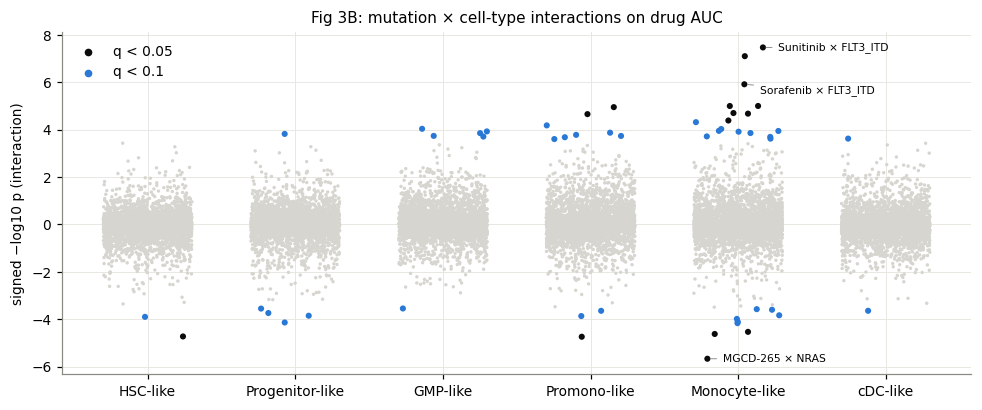

In [23]:
fig, ax = plt.subplots(figsize=(9, 3.8))
xpos = {c: i for i, c in enumerate(CELL_TYPES)}
jit = np.random.default_rng(0).uniform(-0.3, 0.3, len(inter))
sl = np.sign(inter.t) * -np.log10(inter.p)
col = np.where(inter.q < .05, INK, np.where(inter.q < .1, "#2a78d6", "#d6d5cf"))
ax.scatter(inter.cell_type.map(xpos) + jit, sl, s=np.where(inter.q < .1, 16, 5), c=col, linewidth=0)
# label the paper's highlighted example plus the strongest hit in each direction (full list printed above)
lab_idx = {inter[(inter.q < .05) & (inter.t > 0)].p.idxmin(), inter[(inter.q < .05) & (inter.t < 0)].p.idxmin(),
           inter[inter.inhibitor.str.startswith("Sorafenib") & (inter.alteration == "FLT3_ITD")
                 & (inter.cell_type == "Monocyte-like")].index[0]}
for i, (dx, dy) in zip(sorted(lab_idx, key=lambda i: -sl[i]), [(10, 0), (10, -4), (10, 0)]):
    ax.annotate(f"{inter.inhibitor[i].split(' (')[0]} × {inter.alteration[i]}", (xpos[inter.cell_type[i]] + jit[i], sl[i]),
                fontsize=7, xytext=(dx, dy), textcoords="offset points", va="center",
                arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.6))
ax.set_xticks(range(6), CELL_TYPES); ax.set_ylabel("signed −log10 p (interaction)")
ax.scatter([], [], c=INK, s=16, label="q < 0.05"); ax.scatter([], [], c="#2a78d6", s=16, label="q < 0.1")
ax.legend(frameon=False, loc="upper left"); ax.set_title("Fig 3B: mutation × cell-type interactions on drug AUC")
plt.tight_layout(); plt.show()

**Interpretation.** As in the paper, most significant interactions involve the **Monocyte-like** score, and FLT3-ITD dominates.
The paper's highlighted example is sorafenib, plotted below (Fig S3B): each panel shows AUC vs cell-type score, split by
FLT3-ITD status.

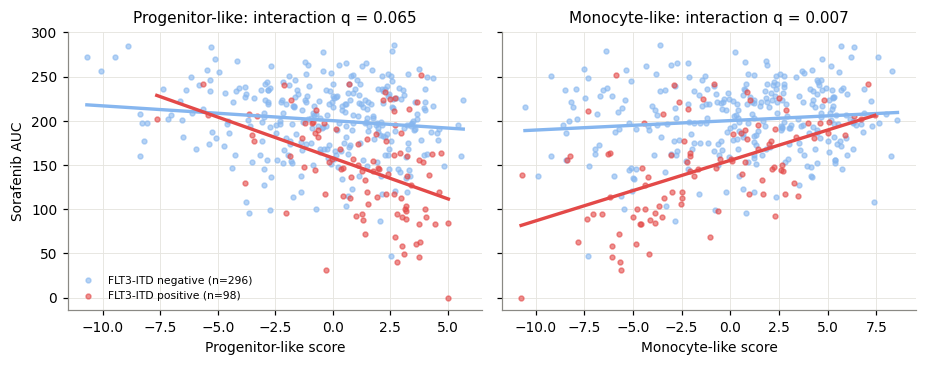

In [24]:
sor = [d for d in A.columns if d.startswith("Sorafenib")][0]
d_ = fm[["mut.FLT3_ITD", "Progenitor-like", "Monocyte-like"]].join(A[sor].rename("AUC")).dropna()
fig, axes = plt.subplots(1, 2, figsize=(8.5, 3.4), sharey=True)
for ax, c in zip(axes, ["Progenitor-like", "Monocyte-like"]):
    for status, colr, lab in [(0, "#86b6ef", "FLT3-ITD negative"), (1, "#e34948", "FLT3-ITD positive")]:
        s = d_[d_["mut.FLT3_ITD"] == status]
        ax.scatter(s[c], s.AUC, s=10, color=colr, alpha=0.6, label=f"{lab} (n={len(s)})")
        b1, b0 = np.polyfit(s[c], s.AUC, 1); xs = np.linspace(s[c].min(), s[c].max(), 2)
        ax.plot(xs, b0 + b1 * xs, color=colr, lw=2.2)
    q_ = inter[(inter.inhibitor == sor) & (inter.alteration == "FLT3_ITD") & (inter.cell_type == c)].q.iloc[0]
    ax.set_title(f"{c}: interaction q = {q_:.3f}"); ax.set_xlabel(f"{c} score")
axes[0].set_ylabel("Sorafenib AUC"); axes[0].legend(frameon=False, fontsize=7)
plt.tight_layout(); plt.show()

**Interpretation.** In FLT3-ITD positive patients (red), sorafenib AUC **rises steeply** with Monocyte-like score. FLT3-ITD
tumors that are monocytic lose most of their sensitivity. With Progenitor-like the pattern reverses: sensitivity is strongest
in FLT3-ITD tumors that are also progenitor-like. Wild-type patients (light blue) show little slope either way. This matches
the paper's statement. Clinically, a mutation alone may not predict response: the cell state it occurs in matters too.

---
## Part 4: Drug families (Figures 4, 5)

**The question.** Single drugs are noisy, and each was tested on a different subset of patients. If we pool drugs that hit the
same target family (e.g. all FLT3/KIT "Type III RTK" inhibitors), do we get cleaner signals?

**Inputs.** `beataml_drug_families.xlsx` maps each drug to one or more target families. The authors built it from target
databases (Targetome, KINOMEscan) plus manual curation.

**Method: single-sample GSEA (ssGSEA), per patient.**
1. **Rescale AUC** so drugs with different dose ranges are comparable: `AUC / (100 × log10(max dose / min dose))`, roughly the
   fraction of the maximum possible area.
2. **Rank** all drugs tested on that patient from most resistant (top) to most sensitive (bottom).
3. **Walk down the ranking.** At each drug, a running sum goes *up* if the drug is in the family (a weighted step, α = 0.25)
   and *down* otherwise. The **ssGSEA score** is the total area under this running sum. It is large and positive if the
   family's drugs cluster at the top (this patient is **resistant** to the family) and negative if they cluster at the bottom
   (**sensitive**).
4. Families need ≥ 5 drugs tested on the patient, and ≥ 50 patients with a score.

Why ssGSEA rather than a PC1 like the cell types? Each patient was tested on a different set of drugs, and PCA can't handle a
matrix that's mostly missing. ssGSEA scores each patient on whatever drugs they have.

This reimplements GSVA 1.38's `ssgsea` (the version the authors used) with `ssgsea.norm = FALSE`.

In [25]:
fams = load_drug_families()
fam_sets = fams["drug_family"].groupby("family").inhibitor.apply(list).to_dict()
inh["perc_max"] = inh.auc / ((np.log10(inh.max_conc) - np.log10(inh.min_conc)) * 100)
PM = inh.pivot_table(index="inhibitor", columns="ptid", values="perc_max")         # drugs x patients (all statuses)

def ssgsea(values, sets, alpha=0.25, min_size=5):
    names = values.index.to_numpy()
    R = stats.rankdata(values.to_numpy(float)).astype(int)            # GSVA: as.integer(rank(x))
    order = np.argsort(-R, kind="stable")                             # highest value (most resistant) first
    w = R[order].astype(float) ** alpha
    ranked = names[order]
    res = {}
    for fam, members in sets.items():
        hit = np.isin(ranked, members)
        if hit.sum() < min_size:
            continue
        walk = np.cumsum(w * hit) / (w * hit).sum() - np.cumsum(~hit) / (~hit).sum()
        res[fam] = walk.sum()
    return res

SS = pd.DataFrame({pt: ssgsea(PM[pt].dropna(), fam_sets) for pt in PM.columns}).T   # patients x families
SS = SS.loc[:, SS.notna().sum() > 50]
short = fams["synonyms"].set_index("family").synonym.to_dict()
print(f"family scores: {SS.shape[0]} patients x {SS.shape[1]} families")

family scores: 512 patients x 26 families


### Fig 4A: overall response by family

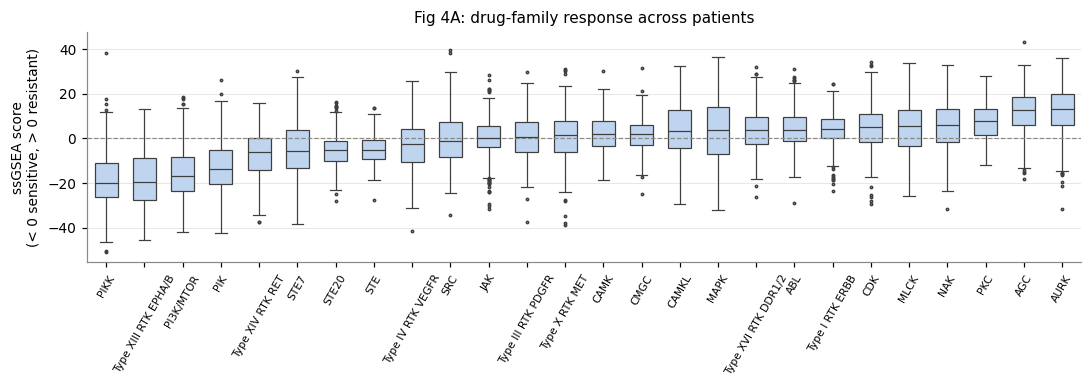

In [26]:
order_f = SS.median().sort_values().index
fig, ax = plt.subplots(figsize=(10, 3.6))
sns.boxplot(data=SS[order_f].rename(columns=short), ax=ax, color="#b7d3f6", fliersize=1.5, width=0.6, linewidth=0.8)
ax.axhline(0, color=MUTED, lw=0.8, ls="--"); ax.tick_params(axis="x", rotation=60, labelsize=7)
ax.set_ylabel("ssGSEA score\n(< 0 sensitive, > 0 resistant)"); ax.set_title("Fig 4A: drug-family response across patients")
plt.tight_layout(); plt.show()

**Interpretation.** Families on the left (e.g. PIKK) are generally potent across patients, and those on the right (e.g. Aurora
kinase, AurK) are generally inactive. This is the paper's Fig 4A ordering.

### Fig 4B: mutation vs family response
Same Welch t-test + Glass's Δ + Storey q-value recipe as Fig 1D, with family scores in place of single drugs.

tests: 810 | significant (q<0.05): 83


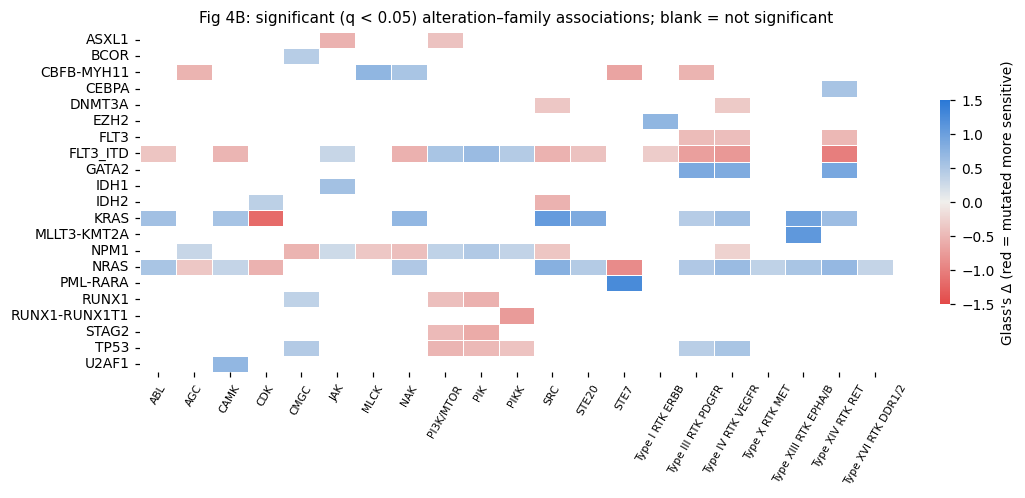

In [27]:
alt_only = feat[ALT].dropna()
fam_mut = welch_assoc(alt_only, SS, min_muts=5)
fam_mut["q"], _ = qvalue(fam_mut.pval)
print(f"tests: {len(fam_mut)} | significant (q<0.05): {(fam_mut.q < .05).sum()}")
sigfm = fam_mut[fam_mut.q < 0.05].copy()
sigfm["family"] = sigfm.outcome.map(short).fillna(sigfm.outcome); sigfm["alt"] = sigfm.gene.str.split(".", n=1).str[1]
H = sigfm.pivot(index="alt", columns="family", values="glass_d")
fig, ax = plt.subplots(figsize=(10, 4.6))
sns.heatmap(H, cmap=DIV, center=0, vmin=-1.5, vmax=1.5, linewidths=0.4, linecolor="white", ax=ax,
            cbar_kws={"label": "Glass's Δ (red = mutated more sensitive)", "shrink": 0.6})
ax.set_xlabel(""); ax.set_ylabel(""); ax.tick_params(axis="x", rotation=60, labelsize=7); ax.grid(False)
ax.set_title("Fig 4B: significant (q < 0.05) alteration–family associations; blank = not significant")
plt.tight_layout(); plt.show()

In [28]:
# Associations called out in the paper's text
call = sigfm.set_index(["alt", "family"])[["n_mut", "glass_d", "q"]]
for alt, fam in [("FLT3_ITD", "Type III RTK PDGFR"), ("NRAS", "STE7"), ("KRAS", "STE7"), ("TP53", "PIK"), ("STAG2", "PIK"),
                 ("RUNX1", "PIK"), ("NRAS", "CDK"), ("KRAS", "CDK")]:
    print(f"{alt:>9} x {fam:<12}", call.loc[(alt, fam)].round(4).to_dict() if (alt, fam) in call.index else "not significant here")

 FLT3_ITD x Type III RTK PDGFR {'n_mut': 110.0, 'glass_d': -0.726, 'q': 0.0}
     NRAS x STE7         {'n_mut': 69.0, 'glass_d': -0.9009, 'q': 0.0}
     KRAS x STE7         not significant here
     TP53 x PIK          {'n_mut': 28.0, 'glass_d': -0.4873, 'q': 0.0128}
    STAG2 x PIK          {'n_mut': 25.0, 'glass_d': -0.6168, 'q': 0.0031}
    RUNX1 x PIK          {'n_mut': 43.0, 'glass_d': -0.5565, 'q': 0.0004}
     NRAS x CDK          {'n_mut': 69.0, 'glass_d': -0.5482, 'q': 0.0001}
     KRAS x CDK          {'n_mut': 22.0, 'glass_d': -1.189, 'q': 0.0035}


**Interpretation.** The expected associations appear: FLT3-ITD with Type III RTK (FLT3/KIT/PDGFR) inhibitors, and NRAS with
MEK (STE7) inhibitors, both sensitizing (red). KRAS × MEK doesn't reach significance here; with only ~22 KRAS-mutant patients it
has much less power than NRAS (69). The paper's "unexpected" findings replicate: TP53, STAG2 and RUNX1 mutant cases are more
sensitive to PI kinase (PIK) inhibitors, and N/KRAS mutant cases to CDK inhibitors.

⚠ **Deviation.** We get 26 families with > 50 scored patients vs the paper's 25. A borderline family probably crosses the
50-patient cut because of a subtle difference in how GSVA 1.38 drops drugs. The direction and size of the main findings don't
depend on this.

### Fig 5A: family response vs cell type
Pearson correlation + BY FDR, as in Fig 3A. Paper: **18 of 25** families correlate with at least one cell type.

families significant for >=1 cell type: 18 of 26   (paper: 18 of 25)


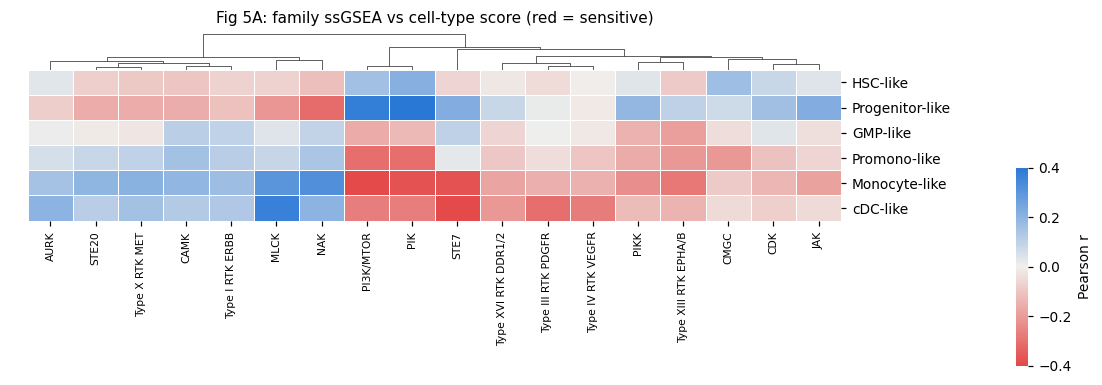

In [29]:
rows = []
for f_ in SS.columns:
    y = SS[f_].reindex(CT.index); ok = y.notna()
    for c in CELL_TYPES:
        r, p = stats.pearsonr(CT.loc[ok, c], y[ok]); rows.append(dict(family=f_, cell_type=c, r=r, p=p))
fam_ct = pd.DataFrame(rows); fam_ct["fdr_BY"] = multipletests(fam_ct.p, method="fdr_by")[1]
sig_f = fam_ct.loc[fam_ct.fdr_BY < .05, "family"].unique()
print(f"families significant for >=1 cell type: {len(sig_f)} of {fam_ct.family.nunique()}   (paper: 18 of 25)")
M5 = fam_ct[fam_ct.family.isin(sig_f)].pivot(index="cell_type", columns="family", values="r").loc[CELL_TYPES].rename(columns=short)
g = sns.clustermap(M5, row_cluster=False, method="average", cmap=DIV, vmin=-0.4, vmax=0.4, figsize=(9, 3.6),
                   linewidths=0.4, linecolor="white", dendrogram_ratio=(0.02, 0.2), cbar_pos=(1.03, 0.12, 0.012, 0.5),
                   cbar_kws={"label": "Pearson r"})
g.ax_heatmap.grid(False)
g.ax_heatmap.set_xlabel(""); g.ax_heatmap.set_ylabel(""); g.ax_heatmap.tick_params(axis="x", labelsize=7)
g.ax_col_dendrogram.set_title("Fig 5A: family ssGSEA vs cell-type score (red = sensitive)"); plt.show()

**Interpretation.** 18 families correlate with maturation state, matching the paper. The same immature-vs-mature split as for
single drugs shows up at the family level. So maturation dependence comes from the drug *targets*, not quirks of single
compounds. (Fig 5B, family × mutation × cell-type interactions, uses the same interaction model as Fig 3B on these scores, so
we skip it.)

---
## Part 5: What predicts survival? (Figures 6, 7)

### Fig 6A: univariate scan of features vs clinical variables
**The question.** Which expression features (9 modules + 6 cell types) relate to clinical variables, and in particular to survival?

**Inputs.** Patients with RNA-seq whose specimen was taken **at initial diagnosis** (paper: **n = 435**). Survival measured from
a relapse sample would mean something different.

**Method.** One regression per (feature, clinical variable), with the feature as the predictor, using whichever model fits the
outcome type. The heatmap shows the test statistic, which is the estimate divided by its standard error, so its sign gives
direction and its size gives strength (|z| > 1.96 ≈ p < 0.05):

| Outcome type | Model | Statistic |
|---|---|---|
| Two-class (e.g. Adverse vs Favorable ELN) | logistic regression | z |
| Continuous (age, WBC, % blasts) | linear regression | t |
| Survival (all patients, and within each age group) | **Cox proportional hazards** | z |

**The Cox model, briefly.** It models the **hazard**, the instantaneous death rate among those still alive, as
`baseline(t) × exp(β × feature)`. The baseline risk over time is left unspecified. β measures how the risk scales with the
feature, and **exp(β) is the hazard ratio** per one-unit increase. A positive z means higher feature → higher risk of death →
shorter survival.

initial-diagnosis RNA-seq patients: 435 (paper: 435)


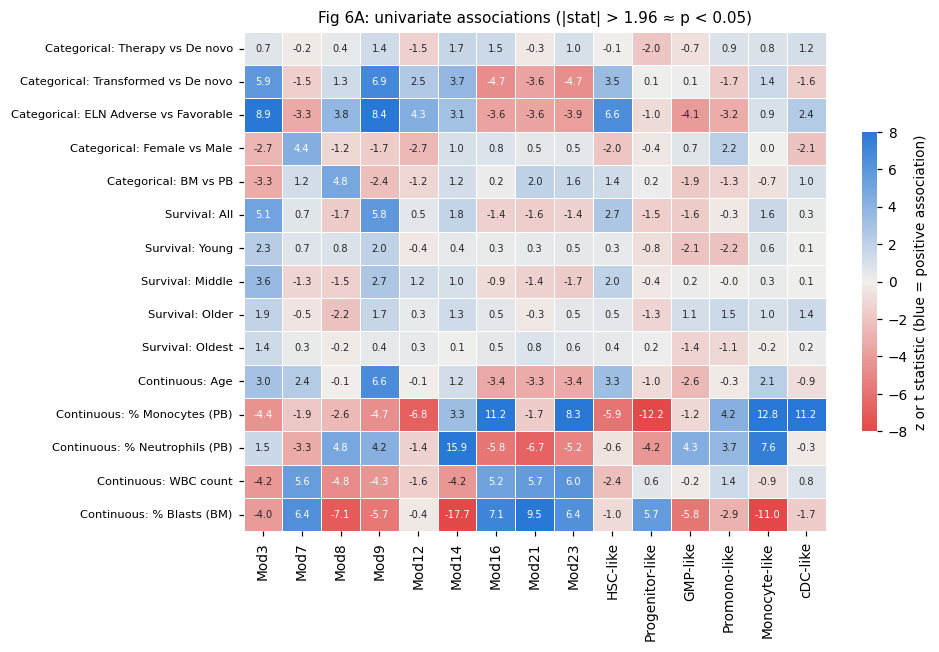

In [30]:
r6 = clin[clin.manuscript_rnaseq.eq("yes") & clin.diseaseStageAtSpecimenCollection.eq("Initial Diagnosis")].set_index("ptid").copy()
print("initial-diagnosis RNA-seq patients:", len(r6), "(paper: 435)")
types = pd.DataFrame({"Denovo": r6.isDenovo.eq("TRUE"), "Transformed": r6.isTransformed.eq("TRUE"),
                      "Therapy": r6.isTherapy.astype(bool)})
r6["type"] = np.where(types.sum(axis=1) == 1, types.idxmax(axis=1), None)    # drop the few with >1 flag
r6["perc_blasts"] = pd.to_numeric(r6["%.Blasts.in.BM"].astype(str).str.replace(">", ""), errors="coerce")
F6 = feat[MODS + CELL_TYPES].dropna()

def logit_z(df, col, ref, alt, x):
    d = df[[col]].join(F6[x]).dropna(); d = d[d[col].isin([ref, alt])]
    fit = sm.Logit((d[col] == alt).astype(float), sm.add_constant(d[x])).fit(disp=0)
    return fit.tvalues[x]
def lm_t(df, col, x):
    d = df[[col]].join(F6[x]).dropna()
    return sm.OLS(d[col].astype(float), sm.add_constant(d[x])).fit().tvalues[x]
def cox_z(df, x):
    d = df[["overallSurvival", "is_dead"]].join(F6[x]).dropna().astype(float)
    return CoxPHFitter().fit(d, "overallSurvival", "is_dead").summary.loc[x, "z"]

cats = {"Therapy vs De novo": ("type", "Denovo", "Therapy"), "Transformed vs De novo": ("type", "Denovo", "Transformed"),
        "ELN Adverse vs Favorable": ("ELN2017", "Favorable", "Adverse"), "Female vs Male": ("consensus_sex", "Male", "Female"),
        "BM vs PB": ("specimenType", "Peripheral Blood", "Bone Marrow Aspirate")}
conts = {"Age": "ageAtDiagnosis", "% Monocytes (PB)": "%.Monocytes.in.PB", "% Neutrophils (PB)": "%.Neutrophils.in.PB",
         "WBC count": "wbcCount", "% Blasts (BM)": "perc_blasts"}
res = {}
for x in MODS + CELL_TYPES:
    col = {}
    for k, (c_, ref, alt) in cats.items(): col[("Categorical", k)] = logit_z(r6, c_, ref, alt, x)
    col[("Survival", "All")] = cox_z(r6, x)
    for ag in ["young", "middle", "older", "oldest"]: col[("Survival", ag.capitalize())] = cox_z(r6[r6.age_cut == ag], x)
    for k, c_ in conts.items(): col[("Continuous", k)] = lm_t(r6, c_, x)
    res[x.replace("M", "Mod") if x in MODS else x] = col
assoc6 = pd.DataFrame(res)
fig, ax = plt.subplots(figsize=(9, 6))
sns.heatmap(assoc6, cmap=DIV, center=0, vmin=-8, vmax=8, annot=True, fmt=".1f", annot_kws={"size": 6.5}, linewidths=0.4,
            linecolor="white", ax=ax, cbar_kws={"label": "z or t statistic (blue = positive association)", "shrink": 0.6})
ax.set_yticklabels([f"{a}: {b}" for a, b in assoc6.index], fontsize=7.5); ax.set_xlabel(""); ax.set_ylabel(""); ax.grid(False)
ax.set_title("Fig 6A: univariate associations (|stat| > 1.96 ≈ p < 0.05)"); plt.tight_layout(); plt.show()

**Interpretation.** Look at the **Survival** rows. Positive (blue) values mean a higher feature score goes with shorter survival.
* **Mod3 (z = 5.1) and Mod9 (z = 5.8)** have by far the strongest survival associations, and **HSC-like** is next (z = 2.7). The
  paper says the same: "modules 3 and 9 showed the strongest associations with survival". Mod12 sits in the same cluster
  because its pattern across *all* rows is similar (high in Adverse ELN and transformed AML), even though its own survival z is
  small.
* Within age groups the signals shrink because the groups are small. Mod3 is significant in young (2.3) and middle (3.6)
  patients. In older patients, other factors (age itself, TP53) dominate.
* Mod3 and Mod9 are also strongly higher in **Adverse ELN** (z ≈ 9) and in **transformed AML** (secondary AML from prior MDS/MPN,
  known to do worse). So part of their survival signal overlaps known risk factors. The forest below asks what remains.
* Sanity checks: Monocyte-like and cDC-like scores track the % monocytes in blood (t ≈ 11–13), and Mod14 tracks neutrophils.

### Fig 6B: PEAR1 is the hub of Module 3
**Method: kME (module membership).** For each gene in Module 3, correlate its expression with the module eigengene. A gene with
very high kME is a "hub": it captures the module almost by itself. Following WGCNA's `signedKME(corFnc = "bicor")`, the
correlation is the **biweight midcorrelation**, a robust version of Pearson that down-weights outliers (points more than ~9
median absolute deviations from the median get zero weight). The authors pass `maxPOutliers = 0.1`, so at most 10% of points
on each side are treated as outliers.

Module 3: 203 genes (paper: 203). Top kME:
PEAR1      0.814
IGHJ1      0.716
SETBP1     0.711
F2RL1      0.703
LRP6       0.699
FAM171B    0.694


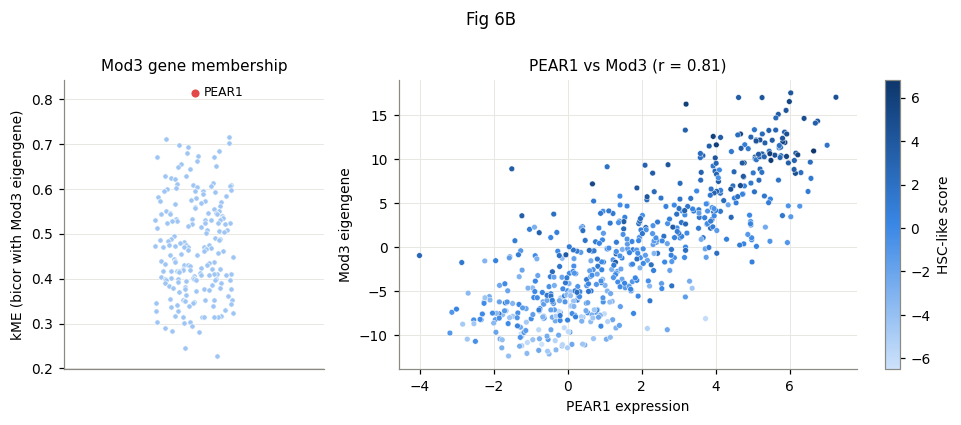

In [31]:
def bicor(Xm, y, max_p_outliers=0.1):
    # Biweight midcorrelation of each column of Xm with y (WGCNA bicor with maxPOutliers)
    def weights(a):
        med = np.median(a, axis=0); mad = np.median(np.abs(a - med), axis=0)
        u = (a - med) / (9 * mad)
        for side, q in ((a > med, 1 - max_p_outliers), (a < med, max_p_outliers)):
            uq = np.abs(np.quantile(a, q, axis=0) - med) / (9 * mad)       # u at the 10%/90% quantile
            u = np.where(side & (uq > 1), u / np.where(uq > 1, uq, 1), u)  # widen so <=10% are outliers
        w = (1 - u ** 2) ** 2 * (np.abs(u) < 1)
        xt = (a - med) * w
        return xt / np.sqrt((xt ** 2).sum(axis=0))
    return (weights(Xm) * weights(y[:, None])).sum(axis=0)

m3_genes = wg[wg.cur_labels.eq("M3")].display_label.tolist()
kme = pd.Series(bicor(X[m3_genes].to_numpy(float), ME["M3"].to_numpy()), index=m3_genes).sort_values(ascending=False)
print(f"Module 3: {len(m3_genes)} genes (paper: 203). Top kME:"); print(kme.head(6).round(3).to_string())

fig, (a1, a2) = plt.subplots(1, 2, figsize=(9, 3.8), width_ratios=[1, 2.2])
jx = np.random.default_rng(1).uniform(-0.15, 0.15, len(kme))
a1.scatter(jx, kme, s=12, color="#9ec5f4", edgecolor="white", linewidth=0.4)
a1.scatter(jx[0], kme.iloc[0], s=40, color="#e34948", edgecolor="white", zorder=3)
a1.annotate("PEAR1", (jx[0], kme.iloc[0]), xytext=(6, -2), textcoords="offset points", fontsize=8)
a1.set_xticks([]); a1.set_xlim(-0.5, 0.5); a1.set_ylabel("kME (bicor with Mod3 eigengene)"); a1.set_title("Mod3 gene membership")
sc = a2.scatter(X["PEAR1"], ME["M3"], c=CT["HSC-like"], cmap=SEQ, s=14, edgecolor="white", linewidth=0.3)
plt.colorbar(sc, ax=a2, label="HSC-like score"); a2.set_xlabel("PEAR1 expression"); a2.set_ylabel("Mod3 eigengene")
a2.set_title(f"PEAR1 vs Mod3 (r = {np.corrcoef(X['PEAR1'], ME['M3'])[0,1]:.2f})")
plt.suptitle("Fig 6B", y=1.0); plt.tight_layout(); plt.show()

**Interpretation.** PEAR1's kME (≈ 0.81) is well clear of the next gene (≈ 0.72). The paper's point is that one gene
"stands in" for the whole 203-gene module. The right panel shows PEAR1, Mod3 and HSC-like score rising together (darker
points sit top-right), so PEAR1 marks stem-like tumors.

### Fig 6C: a survival forest, and which variables matter most
**The question.** With everything in one model (age group, modules, cell types, mutations, fusions), which variables best
separate patients with short and long survival?

**Inputs.** **De novo** AML with RNA-seq and survival, complete data (paper: n = 298). Secondary AML is excluded because AML
type is entangled with many of the other variables.

**Method.**
1. **Conditional inference forest (`cforest`).** Grow 1,000 survival trees, each on a random **63.2% subsample without
   replacement** (Strobl et al. recommend this over the bootstrap to avoid biased variable selection). Each tree considers a
   random √p subset of variables at each split and chooses splits with a **log-rank** criterion. Averaging over trees gives
   each patient a predicted survival curve. Following the authors, we use **out-of-bag** predictions: each patient is
   predicted only by trees that never saw them. From each curve we take the predicted **median survival**.
2. **Surrogate tree.** A 1,000-tree forest can't be read, so a single tree is fit to *predict the forest's predictions*
   (log10 median survival). The tree's splits summarize what the forest learned. The paper's surrogate agrees with the
   forest at r = 0.877.

⚠ **Deviation.** R's `partykit` has no Python port. Step 1 here uses `sksurv.SurvivalTree` (log-rank splits, √p variables,
min 20 per split / 7 per leaf, as in `ctree_control` defaults) on 63.2% subsamples, which is close to `cforest` but not
identical: `cforest` picks variables with permutation tests. Step 2 uses a CART regression tree (max depth 3, ≥ 20 patients per
leaf) in place of `ctree`'s significance-based stopping. Expect the same leading variables, not an identical tree.

de novo patients with complete data: 299 (paper: 298) | deaths: 137 | variables: 52


surrogate tree vs forest predictions: r = 0.784 (paper: 0.877)


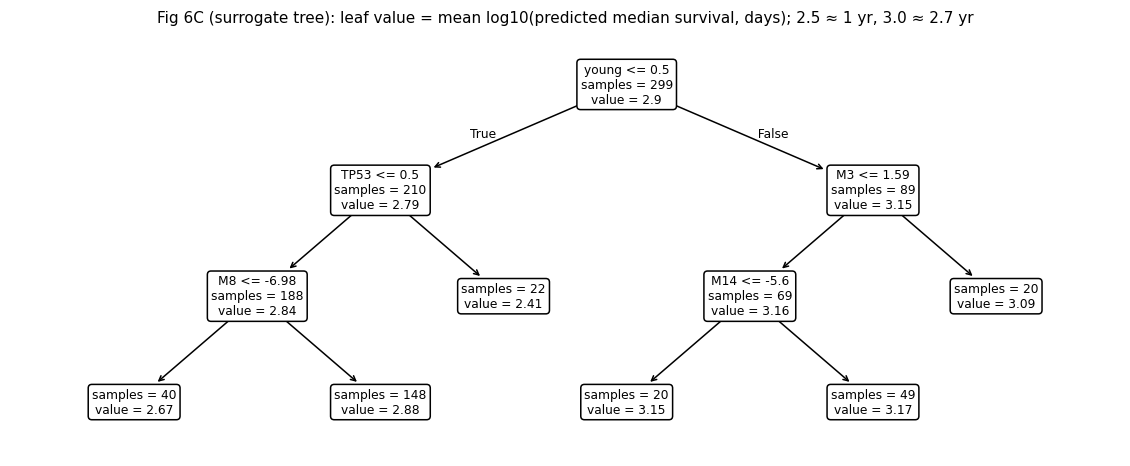

In [32]:
from sksurv.tree import SurvivalTree
from sksurv.util import Surv
from sklearn.tree import DecisionTreeRegressor, plot_tree

r6c = clin[clin.manuscript_rnaseq.eq("yes") & clin.isDenovo.eq("TRUE") & clin.overallSurvival.notna() & clin.is_dead.notna()].set_index("ptid")
df6c = (pd.get_dummies(r6c.age_cut).astype(int).join(r6c[["overallSurvival", "is_dead"]]).join(feat, how="inner").dropna())
Xf = df6c.drop(columns=["overallSurvival", "is_dead"]).astype(float)
Xf.columns = [c.split(".", 1)[1] if c.startswith(("mut.", "fus.")) else c for c in Xf.columns]
ysurv = Surv.from_arrays(df6c.is_dead.astype(bool), df6c.overallSurvival)
n, p = Xf.shape
print(f"de novo patients with complete data: {n} (paper: 298) | deaths: {int(df6c.is_dead.sum())} | variables: {p}")

rng = np.random.default_rng(3252)                       # the authors' seed (different RNG, so not the same draws)
times = np.unique(df6c.overallSurvival)
S_sum, n_oob = np.zeros((n, len(times))), np.zeros(n)
for b in range(1000):
    inbag = rng.choice(n, size=round(0.632 * n), replace=False)
    oob = np.setdiff1d(np.arange(n), inbag)
    tree = SurvivalTree(max_features=int(np.ceil(np.sqrt(p))), min_samples_split=20, min_samples_leaf=7,
                        random_state=int(rng.integers(1e9))).fit(Xf.iloc[inbag], ysurv[inbag])
    surv_fn = tree.predict_survival_function(Xf.iloc[oob], return_array=True)
    pos = np.searchsorted(tree.unique_times_, times, side="right") - 1        # put each tree on a common time grid
    S_sum[oob] += np.where(pos >= 0, surv_fn[:, np.clip(pos, 0, None)], 1.0); n_oob[oob] += 1
S_oob = S_sum / n_oob[:, None]
med_surv = np.array([times[np.argmax(s <= 0.5)] if (s <= 0.5).any() else np.inf for s in S_oob])
med_surv[np.isinf(med_surv)] = med_surv[np.isfinite(med_surv)].max()          # as in the R code
log_pred = np.log10(med_surv)

surrogate = DecisionTreeRegressor(max_depth=3, min_samples_leaf=20, random_state=0).fit(Xf, log_pred)
print(f"surrogate tree vs forest predictions: r = {np.corrcoef(surrogate.predict(Xf), log_pred)[0,1]:.3f} (paper: 0.877)")
fig, ax = plt.subplots(figsize=(13, 5))
plot_tree(surrogate, feature_names=list(Xf.columns), filled=False, impurity=False, rounded=True, fontsize=8, ax=ax,
          precision=2)
ax.set_title("Fig 6C (surrogate tree): leaf value = mean log10(predicted median survival, days); 2.5 ≈ 1 yr, 3.0 ≈ 2.7 yr")
plt.show()

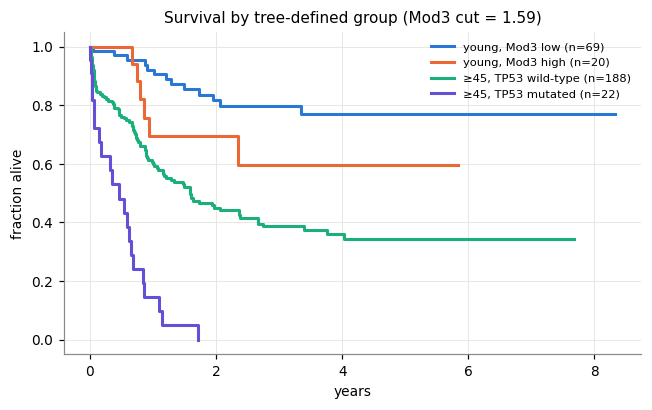

In [33]:
# Survival in the groups the tree defines: young split by Mod3, non-young split by TP53
m3_nodes = np.where(surrogate.tree_.feature == list(Xf.columns).index("M3"))[0]
cut_m3 = surrogate.tree_.threshold[m3_nodes[0]] if len(m3_nodes) else Xf.loc[Xf.young == 1, "M3"].median()
grp = np.select([(Xf.young == 1) & (Xf.M3 <= cut_m3), (Xf.young == 1) & (Xf.M3 > cut_m3),
                 (Xf.young == 0) & (Xf.TP53 == 0), (Xf.young == 0) & (Xf.TP53 == 1)],
                ["young, Mod3 low", "young, Mod3 high", "≥45, TP53 wild-type", "≥45, TP53 mutated"], default="other")
fig, ax = plt.subplots(figsize=(6, 3.8))
for g_, colr in zip(["young, Mod3 low", "young, Mod3 high", "≥45, TP53 wild-type", "≥45, TP53 mutated"],
                    ["#2a78d6", "#eb6834", "#1baf7a", "#6250d6"]):
    s = grp == g_
    KaplanMeierFitter(label=f"{g_} (n={s.sum()})").fit(df6c.overallSurvival[s] / 365.25, df6c.is_dead[s].astype(bool)) \
        .plot_survival_function(ax=ax, ci_show=False, color=colr, lw=2)
ax.set_xlabel("years"); ax.set_ylabel("fraction alive"); ax.legend(frameon=False, fontsize=7.5)
ax.set_title(f"Survival by tree-defined group (Mod3 cut = {cut_m3:.2f})"); plt.tight_layout(); plt.show()

**Interpretation.** The forest picks the paper's variables. The first split is **age** (young vs not). Among older patients
the next most important variable is **TP53 mutation** (worst outcome). Among **young** patients the split is on **Mod3**. So
for patients under 45, where age and TP53 explain less, the Mod3 / PEAR1 program is the strongest determinant of outcome,
which is the paper's Fig 6C conclusion.

Two honest caveats:
* The leaf values for young patients barely differ (3.09 vs 3.15). Many young patients' predicted survival curves never drop
  below 50%, so their "median survival" is capped at the longest follow-up, which compresses the differences. The KM plot
  shows the real separation better.
* Our surrogate tree agrees with the forest at r ≈ 0.78, vs the paper's 0.877. The paper's `ctree` can grow deeper wherever
  splits stay significant, and a depth-4 CART tree here reaches ≈ 0.85. A shallower tree is easier to read. Lower-level splits
  (Mod8, Mod14) are not in the paper's tree and shouldn't be over-read.

### Fig 7A: PEAR1 vs ELN risk, by age
**The question.** Is PEAR1 just a re-encoding of the standard ELN 2017 genetic risk classification? If PEAR1 were simply
higher in "Adverse" patients, it would add little new information.

**Method.** Welch t-test of PEAR1 expression, Adverse vs Favorable, within each age group (older and oldest pooled). Paper:
young +0.762, p = 0.170, n = 79 / middle +1.497, p = 0.0063, n = 72 / older+oldest +3.765, p = 3.3 × 10⁻²⁵, n = 172.

         age   n mean_diff        p
       young  79     0.762     0.17
      middle  72     1.497  0.00633
older+oldest 172     3.765 3.28e-25


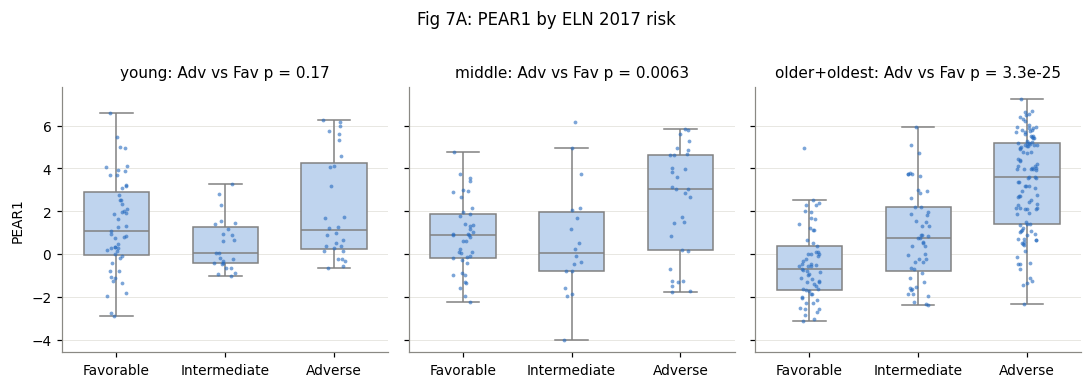

In [34]:
p1 = rna_clin.assign(PEAR1=X["PEAR1"])
p1["age_cat"] = p1.age_cut.astype(str).replace({"older": "older+oldest", "oldest": "older+oldest"})
rows = []
for ag in ["young", "middle", "older+oldest"]:
    g_ = p1[(p1.age_cat == ag) & p1.ELN2017.isin(["Adverse", "Favorable"])]
    ad, fa = g_.PEAR1[g_.ELN2017 == "Adverse"], g_.PEAR1[g_.ELN2017 == "Favorable"]
    rows.append(dict(age=ag, n=len(g_), mean_diff=ad.mean() - fa.mean(), p=stats.ttest_ind(ad, fa, equal_var=False).pvalue))
print(pd.DataFrame(rows).to_string(index=False, formatters={"p": "{:.3g}".format, "mean_diff": "{:.3f}".format}))

fig, axes = plt.subplots(1, 3, figsize=(10, 3.4), sharey=True)
for ax, ag, row in zip(axes, ["young", "middle", "older+oldest"], rows):
    d = p1[(p1.age_cat == ag) & p1.ELN2017.notna()]
    o = ["Favorable", "Intermediate", "Adverse"]
    sns.boxplot(data=d, x="ELN2017", y="PEAR1", order=o, ax=ax, color="#b7d3f6", fliersize=0, width=0.6)
    sns.stripplot(data=d, x="ELN2017", y="PEAR1", order=o, ax=ax, color="#256abf", size=2.5, alpha=0.6)
    ax.set_title(f"{ag}: Adv vs Fav p = {row['p']:.2g}"); ax.set_xlabel("")
plt.suptitle("Fig 7A: PEAR1 by ELN 2017 risk", y=1.02); plt.tight_layout(); plt.show()

**Interpretation.** Identical to the paper to every printed digit. In older patients PEAR1 is much higher in Adverse-risk cases,
so there it overlaps with ELN. In **young** patients it is *not* significantly different between Adverse and Favorable, yet
(Fig 6C, 7B) it still predicts survival there. So in young patients PEAR1 carries prognostic information that ELN doesn't.

### Fig 7B/C: PEAR1 vs the LSC17 score
**Background.** LSC17 (Ng et al. 2016) is a published prognostic score: a weighted sum of 17 genes from leukemic stem cells.
We compute it with the published coefficients. One gene, SMIM24, is called by its old name C19orf77 in this expression file.

**Method: hazard ratios after a high/low split.** Patients are split into "high" and "low" for PEAR1 and for LSC17, and a
Cox model gives the HR (high vs low) with a 95% confidence interval. If the CI excludes 1, the split significantly separates
survival. Two ways to choose the split:
* **Median split**: the usual way for LSC17.
* **ctree split**: a data-driven cut. First test whether the variable is associated with survival at all, using a linear test
  on **log-rank scores** (each patient's death indicator minus their expected cumulative hazard). If p < 0.05, choose the cut
  that best separates the two groups, with ≥ 20 patients per side. If the test isn't significant, there is no split ("N/A").
  This reimplements `partykit::ctree(maxdepth = 1, minbucket = 20)` for one variable.

**Inputs.** De novo patients with RNA-seq and survival, any timepoint (`pear1.rna.denovo.survival()`), in four subsets: all /
young × all tissues / bone marrow only.

⚠ **Caution.** The ctree cut is chosen to maximize separation and then tested on the same data, so its HR is optimistic. The
median split doesn't have this problem.

In [35]:
LSC17 = dict(DNMT3B=0.0874, ZBTB46=-0.0347, NYNRIN=0.00865, ARHGAP22=-0.0138, LAPTM4B=0.00582, MMRN1=0.0258,
             DPYSL3=0.0284, KIAA0125=0.0196, CDK6=-0.0704, CPXM1=-0.0258, SOCS2=0.0271, C19orf77=-0.0226,  # C19orf77 = SMIM24
             EMP1=0.0146, NGFRAP1=0.0465, CD34=0.0338, AKR1C3=-0.0402, GPR56=0.0501)
p1["LSC17"] = X[list(LSC17)].to_numpy() @ np.array(list(LSC17.values()))
ds = p1[p1.overallSurvival.notna() & p1.is_dead.notna() & p1.isDenovo.eq("TRUE")].copy()
ds["event"] = ds.is_dead.astype(int)
print(f"de novo with survival: {len(ds)} | young: {(ds.age_cut == 'young').sum()} | PEAR1 vs LSC17 r = {ds.PEAR1.corr(ds.LSC17):.2f}")

def logrank_scores(t, e):
    # e_i - NelsonAalen(t_i): the log-rank "residual" for each patient
    d = pd.DataFrame({"t": t, "e": e}).groupby("t").e.agg(["sum", "size"]).sort_index()
    H = (d["sum"] / d["size"][::-1].cumsum()[::-1]).cumsum()
    return e - H.reindex(t).to_numpy()
def linear_stat(x, h):
    # standardized permutation linear statistic sum(x*h) (Strasser-Weber), as used by ctree
    n = len(h); vh = ((h - h.mean()) ** 2).mean()
    return ((x * h).sum() - x.sum() * h.mean()) / np.sqrt(n / (n - 1) * vh * ((x ** 2).sum() - x.sum() ** 2 / n))
def ctree_cut(x, t, e, minbucket=20, alpha=0.05):
    h = logrank_scores(np.asarray(t, float), np.asarray(e, float)); x = np.asarray(x, float)
    if 2 * stats.norm.sf(abs(linear_stat(x, h))) >= alpha:
        return None                                                    # no significant association -> no split
    best, cut = -1, None
    for c in np.unique(x)[:-1]:
        left = x <= c
        if minbucket <= left.sum() <= len(x) - minbucket:
            s = linear_stat(left.astype(float), h) ** 2
            if s > best: best, cut = s, c
    return cut
def hr_split(d, col, how):
    cut = d[col].median() if how == "median" else ctree_cut(d[col], d.overallSurvival, d.event)
    if cut is None:
        return dict(HR=np.nan, lo=np.nan, hi=np.nan, p=np.nan, n_high=np.nan, cut=np.nan)
    dd = pd.DataFrame({"T": d.overallSurvival, "E": d.event, "high": (d[col] > cut).astype(int)})
    s = CoxPHFitter().fit(dd, "T", "E").summary.loc["high"]
    return dict(HR=s["exp(coef)"], lo=s["exp(coef) lower 95%"], hi=s["exp(coef) upper 95%"], p=s.p, n_high=int(dd.high.sum()), cut=cut)

subsets = {"All / all tissue": ds, "Young / all tissue": ds[ds.age_cut == "young"],
           "All / BM": ds[ds.specimenType.eq("Bone Marrow Aspirate")],
           "Young / BM": ds[(ds.age_cut == "young") & ds.specimenType.eq("Bone Marrow Aspirate")]}
hr_tab = pd.DataFrame([dict(subset=k, score=c, split=how, n=len(v), **hr_split(v, c, how))
                       for k, v in subsets.items() for c in ["PEAR1", "LSC17"] for how in ["median", "ctree"]])
print(hr_tab.round(3).to_string(index=False))

de novo with survival: 312 | young: 93 | PEAR1 vs LSC17 r = 0.37


            subset score  split   n    HR    lo     hi     p  n_high   cut
  All / all tissue PEAR1 median 312 1.172 0.842  1.630 0.347   156.0 0.800
  All / all tissue PEAR1  ctree 312   NaN   NaN    NaN   NaN     NaN   NaN
  All / all tissue LSC17 median 312 1.773 1.266  2.482 0.001   156.0 0.307
  All / all tissue LSC17  ctree 312 2.934 1.842  4.673 0.000   229.0 0.068
Young / all tissue PEAR1 median  93 2.508 1.011  6.223 0.047    46.0 0.833
Young / all tissue PEAR1  ctree  93 3.532 1.187 10.515 0.023    55.0 0.329
Young / all tissue LSC17 median  93 4.142 1.512 11.347 0.006    46.0 0.216
Young / all tissue LSC17  ctree  93 5.710 2.077 15.697 0.001    39.0 0.342
          All / BM PEAR1 median 193 1.345 0.875  2.069 0.177    96.0 0.657
          All / BM PEAR1  ctree 193 1.865 1.212  2.872 0.005    70.0 1.354
          All / BM LSC17 median 193 2.216 1.420  3.456 0.000    96.0 0.290
          All / BM LSC17  ctree 193 3.769 1.996  7.120 0.000   137.0 0.068
        Young / BM PEAR1 

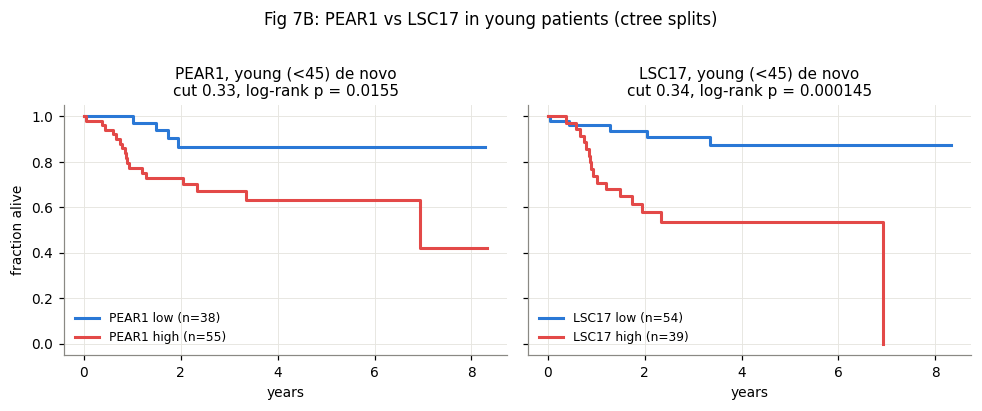

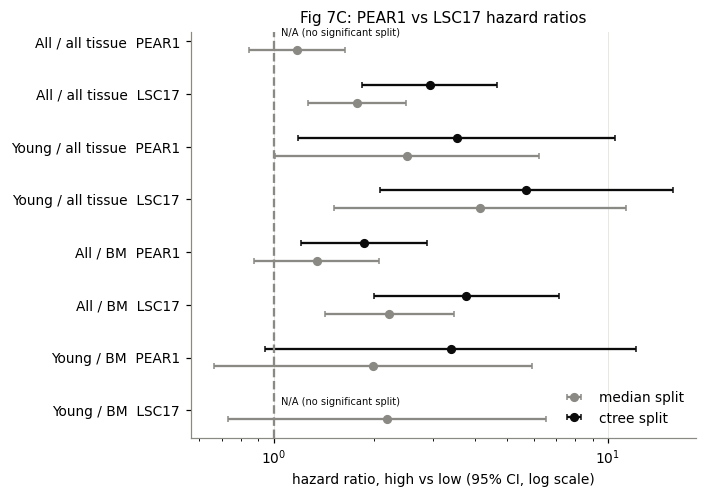

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), sharey=True)
young = ds[ds.age_cut == "young"]
for ax, c in zip(axes, ["PEAR1", "LSC17"]):
    cut = ctree_cut(young[c], young.overallSurvival, young.event)
    for lab, s, colr in [("low", young[c] <= cut, "#2a78d6"), ("high", young[c] > cut, "#e34948")]:
        KaplanMeierFitter(label=f"{c} {lab} (n={s.sum()})").fit(young.overallSurvival[s] / 365.25, young.event[s]) \
            .plot_survival_function(ax=ax, ci_show=False, color=colr, lw=2)
    lr_ = logrank_test(young.overallSurvival[young[c] <= cut], young.overallSurvival[young[c] > cut],
                       young.event[young[c] <= cut], young.event[young[c] > cut])
    ax.set_title(f"{c}, young (<45) de novo\ncut {cut:.2f}, log-rank p = {lr_.p_value:.3g}")
    ax.set_xlabel("years"); ax.legend(frameon=False, fontsize=8)
axes[0].set_ylabel("fraction alive"); plt.suptitle("Fig 7B: PEAR1 vs LSC17 in young patients (ctree splits)", y=1.02)
plt.tight_layout(); plt.show()

# Fig 7C: forest plot of hazard ratios
fig, ax = plt.subplots(figsize=(6.5, 4.6))
pairs = hr_tab[["subset", "score"]].drop_duplicates().reset_index(drop=True)
ymap = {(r_.subset, r_.score): len(pairs) - 1 - i for i, r_ in pairs.iterrows()}
for how, colr, off in [("median", MUTED, -0.17), ("ctree", INK, 0.17)]:
    s = hr_tab[hr_tab.split == how]
    yy = np.array([ymap[(a, b)] for a, b in zip(s.subset, s.score)]) + off
    ax.errorbar(s.HR, yy, xerr=[s.HR - s.lo, s.hi - s.HR], fmt="o", color=colr, ms=5, capsize=2, label=f"{how} split")
    for y_, v in zip(yy, s.HR):
        if np.isnan(v): ax.text(1.05, y_, "N/A (no significant split)", fontsize=6.5, va="center", color=colr)
ax.axvline(1, ls="--", color=MUTED); ax.set_xscale("log"); ax.set_xlabel("hazard ratio, high vs low (95% CI, log scale)")
ax.set_yticks(list(ymap.values()), [f"{a}  {b}" for a, b in ymap]); ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="lower right")
ax.set_title("Fig 7C: PEAR1 vs LSC17 hazard ratios"); plt.tight_layout(); plt.show()

**Interpretation.**
* **Young patients (all tissues)**: both PEAR1 and LSC17 separate survival (HR 2.5–5.7, CIs above 1, though PEAR1's median-split
  CI only just clears 1 at 1.01). One gene does roughly as well as a 17-gene signature, which is the paper's headline claim.
  LSC17's point estimates are somewhat higher here, and the CIs overlap heavily.
* **All ages**: LSC17 is better. PEAR1's median split isn't significant, and the ctree finds **no significant split** for PEAR1
  (N/A). In older patients PEAR1 mostly overlaps with ELN risk and age (Fig 7A), so it adds less.
* Like the paper, two ctree fits return "N/A" (no significant split). Wide CIs in the young (n = 93) and BM-young (n = 55)
  subsets come from small samples, and in BM-young neither score is significant.
* Overall the paper's wording, "PEAR1 performs similarly to LSC17", holds best in the young subgroup. It is also a single-cohort
  finding: the paper validates it externally in TCGA and Malani et al., which we don't reproduce here.

---
## Summary: paper vs this replication

In [37]:
yb = hr_tab.set_index(["subset", "score", "split"])
summary = pd.DataFrame([
    ("1A", "mean mutation-frequency difference (pp)", "1.037", f"{100*freq['diff'].mean():.3f}"),
    ("1B", "log-rank by cohort", "χ² 1.3, p = 0.2", f"χ² {lr.test_statistic:.2f}, p = {lr.p_value:.2f}"),
    ("1C", "de novo mean AUC, r", "0.965", f"{stats.pearsonr(mean_auc['Waves1+2'], mean_auc['Waves3+4'])[0]:.3f}"),
    ("1D", "mutation–drug concordance", "213/239 (89%)", f"{agree}/{len(sig12)} ({agree/len(sig12):.0%})"),
    ("2", "PC1 cell-type scores vs published", "-", f"r = {check['r with published'].min():.4f} (all 6)"),
    ("2A", "non-redundant WGCNA modules", "9", f"{len(MODS)}"),
    ("3A", "drugs correlated with ≥1 cell type (BY<0.05)", "73", f"{len(sig_drugs)}"),
    ("5A", "families correlated with ≥1 cell type", "18 of 25", f"{len(sig_f)} of {fam_ct.family.nunique()}"),
    ("6A", "initial-diagnosis RNA-seq patients", "435", f"{len(r6)}"),
    ("6B", "top kME gene in Mod3", "PEAR1", kme.index[0]),
    ("6C", "de novo complete cases for forest", "298", f"{n}"),
    ("7A", "PEAR1 Adv-Fav, older+oldest", "3.765, p = 3.3e-25", f"{rows[2]['mean_diff']:.3f}, p = {rows[2]['p']:.2g}"),
    ("7A", "PEAR1 Adv-Fav, young", "p = 0.170", f"p = {rows[0]['p']:.3f}"),
    ("7C", "ctree fits with no split", "2", f"{hr_tab[hr_tab.split=='ctree'].HR.isna().sum()}"),
], columns=["figure", "quantity", "paper", "this notebook"])
summary

,figure,quantity,paper,this notebook
0,1A,mean mutation-frequency difference (pp),1.037,1.035
1,1B,log-rank by cohort,"χ² 1.3, p = 0.2","χ² 1.32, p = 0.25"
2,1C,"de novo mean AUC, r",0.965,0.965
3,1D,mutation–drug concordance,213/239 (89%),213/239 (89%)
4,2,PC1 cell-type scores vs published,-,r = 1.0000 (all 6)
5,2A,non-redundant WGCNA modules,9,9
6,3A,drugs correlated with ≥1 cell type (BY<0.05),73,73
7,5A,families correlated with ≥1 cell type,18 of 25,18 of 26
8,6A,initial-diagnosis RNA-seq patients,435,435
9,6B,top kME gene in Mod3,PEAR1,PEAR1


### What this means

* **The core pipeline reproduces exactly.** Cohort definitions, mutation matrix, Welch/Storey testing, the PC1 cell-type scores,
  WGCNA eigengenes and the cell-type/drug correlations all hit the paper's numbers to the stated precision. So the
  `paper_score()` baseline in this repo **is** the paper's baseline.
* **Where it differs, it's because of software, not the data.** The survival forest and ctree splits use Python stand-ins for
  R's `partykit`. The family scores differ by one borderline family. Qualitative conclusions are unchanged.

### Caveats worth keeping in mind (useful for the project write-up)

1. **The PC1 scores are fit on Waves 1+2.** Comparing a new model to them under random CV leaks information. Use the
   Waves 1+2 → 3+4 split, or refit `paper_score()` inside each fold. The function takes a `train` mask, so this is easy.
2. **The cell-type scores aren't independent.** HSC-like and Monocyte-like are strongly anti-correlated (one maturation axis).
   This is why the authors used BY instead of BH, and why the six scores carry fewer than six dimensions of information.
3. **Everything here is univariate or one interaction at a time.** The 73 drugs and the mutation associations are correlations.
   Maturation state confounds many mutation–drug links (Part 3), which is the paper's own argument for adjusting for cell type.
4. **Data-driven cut points (ctree) overstate HRs.** The median-split HRs are the fairer comparison of PEAR1 and LSC17.
5. **AUC has ceiling effects.** Many curves never drop below 50% viability (see `reports/schema_notes.md`). The paper treats
   AUC as continuous and approximately normal, which is shakiest for drugs that rarely work.